# Exploratory Data Analysis — AI Jobs Market 2026

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, patterns, and relationships before applying modeling or statistical techniques. In EDA projects, analysts use summary statistics, charts, and plots to uncover trends, detect anomalies, test assumptions, and gain insights that guide further data preprocessing, feature selection, or hypothesis generation.

**Steps for an Exploratory Data Analysis (EDA) Project**

1. Data Collection
2. Data Cleaning
3. Data Understanding
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Feature Engineering
8. Outlier Detection
9. Trend and Pattern Analysis
10. Documentation & Reporting

### ai_jobs_2026_unclean dataset

#### Introduction

This dataset contains roughly 50,000 AI and data-related job postings. Each record describes one posting: the job title, experience level and years of experience required, employment type, company size, country and industry, how remote the job is, the education required, the skills asked for, the salary (both in USD and in the local currency), posting and deadline dates, the number of applicants, and a benefits score.

The file is deliberately **"unclean"**. It contains duplicated rows, spelling mistakes (`Senoir`, `Isreal`, `Manufactoring`), inconsistent casing and spacing, many different spellings of the same value (`FT`, `Full time`, `full_time`), placeholder values (`?`, `--`, `unknown`, `missing`), numbers written as text (`66.8k`, `$163,800`, `five`, `approx 72`, `6/10`), a dozen different date formats, and impossible values (negative salaries, `999999999`, 150 years of experience).

The objective of this analysis is to clean the data and then understand what drives **salary** and **demand** in the AI job market: which roles, skills, countries, and industries pay the most, how experience, education, and remote work affect pay, and how hiring changes over time.

#### Import the necessary libraries

In [1]:
# remove the warning message
import warnings
warnings.filterwarnings('ignore')
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from collections import Counter

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

### 1. Data Collection

* The data comes from a single CSV file (`ai_jobs_2026_unclean.csv`) with one row per job posting.
* All columns are loaded as **text** (`dtype=str`) on purpose. Many numeric columns contain text such as `?` or `66.8k`, so we convert them ourselves during cleaning instead of letting pandas guess.

In [4]:
# Change the path if your file is stored somewhere else
df = pd.read_csv(r"C:\Datascience\File\Projects\ai_jobs_2026_unclean (1).csv", dtype=str)
raw = df.copy()          # keep an untouched copy to compare before/after cleaning
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (51750, 18)


#### Display the first 5 rows of the dataset

In [ ]:
print(df.head())

     job_id               job_title experience_level years_experience employment_type company_size      company_location    industry remote_ratio education_required  \
0  AIJ28610       ROBOTICS ENGINEER           Senior                7       Full-time       Medium  United Arab Emirates   Logistics           50             Master   
1  AIJ18849      AI Agent Developer             Lead                8       Full-time        Large        United Kingdom  Technology       Hybrid             Master   
2  AIJ44826      AI Agent Developer           Senior               10       full-time        Small             Singapore      Retail          0.0           Bachelor   
3  AIJ02437      AI Agent Developer           Senior                5       Part-time        Small                France   Education            -           Bachelor   
4  AIJ22559  Deep Learning Engineer        Mid Level                4       Full-time        Small        United Kingdom  Automotive            0               

#### Display the last 5 rows of the dataset

In [5]:
print(df.tail())

         job_id                  job_title experience_level years_experience employment_type company_size company_location     industry remote_ratio education_required  \
51745  AIJ25545            Prompt Engineer              Mid          3 years       Full-time       Medium             Oman       Energy         50.0           bachelor   
51746  AIJ48057         AI Product Manager           Senior                5       Full-time        Large            China    Logistics      missing           Bachelor   
51747  AIJ11514  Machine Learning Engineer           Senior                5       Full-time        Large           Poland   Technology            0           Bachelor   
51748  AIJ01689      AI Research Scientist           Senior                7       Full-time        Large              PRC  Healthcare             0           Bachelor   
51749  AIJ05995     Deep Learning Engineer           Senior                8       Full-time        Large      Netherlands       Energy          

#### Quick audit of the raw data

Before cleaning, let us measure how dirty each column is. `nunique` shows how many different spellings exist, and a clean column such as `experience_level` should only have about 5 values.

In [6]:
audit = pd.DataFrame({
    'missing (NaN)': raw.isna().sum(),
    'unique raw values': raw.nunique()
})
print(audit)
print("\nFully duplicated rows:", raw.duplicated().sum())
print("\nRaw experience_level spellings (top 15):")
print(raw['experience_level'].value_counts(dropna=False).head(15))

                      missing (NaN)  unique raw values
job_id                           64              49937
job_title                       310                228
experience_level                624                 78
years_experience               1051                147
employment_type                 644                 56
company_size                    928                 52
company_location                491                210
industry                        948                152
remote_ratio                   1220                 26
education_required             1237                 63
required_skills                1572              38430
salary_usd                     1285               5898
salary_local                   1631              15976
salary_currency                 649                105
posting_date                    651               2712
application_deadline            939               2968
applicants                      958                399
benefits_s

### 2. Data Cleaning

Cleaning plan:

1. Unify placeholders (`?`, `--`, `unknown`, `missing`, blank ...) to real missing values (`NaN`) and trim extra spaces.
2. Remove duplicate rows.
3. Standardize categorical columns (title, experience, employment type, company size, country, industry, education).
4. Convert text numbers to numeric (years of experience, salary, applicants, benefits score, remote ratio) and fix impossible values.
5. Repair salary using the **currency** and the fixed exchange rate between `salary_local` and `salary_usd`.
6. Parse the many date formats.
7. Split the skills text into a clean list.
8. Handle the remaining missing values (drop, impute).

#### Step 2.1 — Unify placeholders and trim spaces

In [7]:
NULL_TOKENS = {'', '-', '--', '?', 'unknown', 'missing', 'nan', 'none', 'n/a', 'tbd', 'not specified', 'asap'}

def tidy(x):
    if pd.isna(x):
        return np.nan
    x = re.sub(r'\s+', ' ', str(x)).strip()          # remove extra / double spaces
    return np.nan if x.lower() in NULL_TOKENS else x

df = df.apply(lambda col: col.map(tidy))
print("Missing values after unifying placeholders:")
print(df.isna().sum())

Missing values after unifying placeholders:
job_id                    64
job_title                525
experience_level        1029
years_experience        1652
employment_type         1044
company_size            1545
company_location         802
industry                1582
remote_ratio            2036
education_required      2024
required_skills         2575
salary_usd              2131
salary_local            2645
salary_currency         1063
posting_date            1237
application_deadline    1696
applicants              1524
benefits_score          3045
dtype: int64


#### Step 2.2 — Remove duplicate rows

In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing exact duplicates:", df.shape)

Exact duplicate rows: 1252
Shape after removing exact duplicates: (50498, 18)


#### Step 2.3 — Standardize categorical columns

Each messy spelling is mapped to one standard label. We first lower-case and strip punctuation to build a lookup key, then map it.

In [9]:
def key(s, keep=r'[^a-z0-9& ]'):
    return s.str.lower().str.replace(keep, '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

# ---------- job title ----------
title_map = {
 'ai agent developer':'AI Agent Developer',
 'ai ethics & governance specialist':'AI Ethics & Governance Specialist','ai ethics & gov specialist':'AI Ethics & Governance Specialist','ai ethics and governance specialist':'AI Ethics & Governance Specialist',
 'ai product manager':'AI Product Manager',
 'ai research scientist':'AI Research Scientist','ai reasearch scientist':'AI Research Scientist','ai research scientst':'AI Research Scientist',
 'ai solutions architect':'AI Solutions Architect',
 'computer vision engineer':'Computer Vision Engineer','computer vison engineer':'Computer Vision Engineer','cv engineer':'Computer Vision Engineer',
 'data analyst':'Data Analyst','data analist':'Data Analyst',
 'data engineer':'Data Engineer','data eng':'Data Engineer','data enginer':'Data Engineer',
 'data scientist':'Data Scientist','data scienctist':'Data Scientist','data scientst':'Data Scientist',
 'deep learning engineer':'Deep Learning Engineer','deep learing engineer':'Deep Learning Engineer','dl engineer':'Deep Learning Engineer',
 'llm engineer':'LLM Engineer','llm enginer':'LLM Engineer',
 'machine learning engineer':'Machine Learning Engineer','machine learnin engineer':'Machine Learning Engineer','machine learning engr':'Machine Learning Engineer','ml eng':'Machine Learning Engineer','ml engineer':'Machine Learning Engineer',
 'mlops engineer':'MLOps Engineer','ml ops engineer':'MLOps Engineer','mlops enginer':'MLOps Engineer',
 'nlp engineer':'NLP Engineer','nlp enginer':'NLP Engineer',
 'prompt engineer':'Prompt Engineer','promt engineer':'Prompt Engineer',
 'robotics engineer':'Robotics Engineer'}
df['job_title'] = key(df['job_title']).map(title_map)

# ---------- experience level, employment type, company size, education ----------
exp_map  = {'entry':'Entry','entry level':'Entry','entrylevel':'Entry','jr':'Entry','junior':'Entry',
            'mid':'Mid','mid level':'Mid','midlevel':'Mid','intermediate':'Mid',
            'senior':'Senior','senoir':'Senior','sr':'Senior',
            'lead':'Lead','team lead':'Lead','lead/principal':'Lead',
            'executive':'Executive','exec':'Executive','executive/clevel':'Executive'}
emp_map  = {'fulltime':'Full-time','full time':'Full-time','ft':'Full-time',
            'parttime':'Part-time','part time':'Part-time','pt':'Part-time',
            'contract':'Contract','contractor':'Contract',
            'freelance':'Freelance','freelancer':'Freelance','freelance/gig':'Freelance'}
size_map = {'small':'Small','s':'Small','startup':'Small','small':'Small',
            'medium':'Medium','m':'Medium','med':'Medium','midsize':'Medium',
            'large':'Large','l':'Large','lrg':'Large','enterprise':'Large'}
edu_map  = {'associate':'Associate','assoc':'Associate','associates':'Associate',
            'bachelor':'Bachelor','bachelors':'Bachelor','bs':'Bachelor','bsc':'Bachelor',
            'master':'Master','masters':'Master','ms':'Master','msc':'Master',
            'phd':'PhD','doctorate':'PhD'}
LETTERS = r'[^a-z/ ]'
for col, m in [('experience_level', exp_map), ('employment_type', emp_map),
               ('company_size', size_map), ('education_required', edu_map)]:
    k = key(df[col], keep=LETTERS)
    print(f"{col:20s} unmapped values:", sorted(set(k.dropna()) - set(m)))
    df[col] = k.map(m)

experience_level     unmapped values: []
employment_type      unmapped values: []
company_size         unmapped values: []
education_required   unmapped values: []


In [10]:
# ---------- country ----------
loc_map = {'united states':'United States','us':'United States','usa':'United States','united states of america':'United States',
 'united kingdom':'United Kingdom','uk':'United Kingdom','england':'United Kingdom','great britain':'United Kingdom',
 'united arab emirates':'United Arab Emirates','uae':'United Arab Emirates',
 'australia':'Australia','austrlia':'Australia','brazil':'Brazil','canada':'Canada',
 'china':'China','china prc':'China','prc':'China','france':'France','germany':'Germany','deutschland':'Germany',
 'india':'India','ireland':'Ireland','irelnd':'Ireland','israel':'Israel','isreal':'Israel','japan':'Japan',
 'netherlands':'Netherlands','the netherlands':'Netherlands','holland':'Netherlands','oman':'Oman',
 'poland':'Poland','polland':'Poland','saudi arabia':'Saudi Arabia','singapore':'Singapore','singapor':'Singapore',
 'south korea':'South Korea','korea':'South Korea','republic of korea':'South Korea','s korea':'South Korea',
 'switzerland':'Switzerland','schweiz':'Switzerland'}
df['company_location'] = key(df['company_location'], keep=r'[^a-z ]').map(loc_map)

# ---------- industry ----------
ind_map = {'automotive':'Automotive','consulting':'Consulting','consultancy':'Consulting','education':'Education',
 'energy':'Energy','finance':'Finance','finance/banking':'Finance','financial services':'Finance','gaming':'Gaming',
 'government':'Government','healthcare':'Healthcare','health care':'Healthcare','logistics':'Logistics',
 'manufacturing':'Manufacturing','manufactoring':'Manufacturing','media':'Media','retail':'Retail',
 'technology':'Technology','tech':'Technology','it / technology':'Technology',
 'telecommunications':'Telecommunications','telecom':'Telecommunications','telecomm':'Telecommunications'}
df['industry'] = key(df['industry'], keep=r'[^a-z/ ]').map(ind_map)

print(df[['job_title','experience_level','employment_type','company_size',
          'company_location','industry','education_required']].nunique())

job_title             16
experience_level       5
employment_type        4
company_size           3
company_location      20
industry              14
education_required     4
dtype: int64


#### Step 2.4 — Convert text to numbers and fix impossible values

In [11]:
WORDS = {'one':1,'two':2,'three':3,'four':4,'five':5,'six':6,'seven':7,'eight':8,'nine':9,'ten':10}

def to_num(x):
    """'66.8k' -> 66800, '$163,800' -> 163800, 'USD 95200' -> 95200, 'five' -> 5, '2+' -> 2, 'approx 72' -> 72"""
    if pd.isna(x):
        return np.nan
    t = str(x).lower().replace(',', '').replace('$', '')
    if t in WORDS:
        return WORDS[t]
    m = re.search(r'-?\d+\.?\d*', t)
    if not m:
        return np.nan
    v = float(m.group())
    return v * 1000 if re.search(r'\d\s*k\b', t) else v

for c in ['years_experience', 'salary_usd', 'salary_local', 'applicants']:
    df[c] = df[c].map(to_num)

# benefits_score: '6/10' -> 6, '6,7' -> 6.7, and some rows use a 0-100 scale (e.g. 67 -> 6.7)
def benefits(x):
    if pd.isna(x):
        return np.nan
    t = str(x).strip()
    if '/' in t:
        return to_num(t.split('/')[0])
    if re.fullmatch(r'\d+,\d+', t):
        t = t.replace(',', '.')
    return to_num(t)
df['benefits_score'] = df['benefits_score'].map(benefits)
df.loc[df['benefits_score'] >= 30, 'benefits_score'] /= 10          # 0-100 scale -> 0-10 scale

# remote_ratio: words, percentages and fractions -> 0 / 50 / 100
def remote(x):
    if pd.isna(x):
        return np.nan
    t = str(x).lower().replace('%', '')
    t = {'on-site':'0', 'onsite':'0', 'hybrid':'50', 'remote':'100'}.get(t, t)
    v = to_num(t)
    if v in (0.5, 1.0) and t != '0.0':
        v *= 100
    return v if v in (0, 50, 100) else np.nan          # 33, 75, 150, 200, -50 are invalid
df['remote_ratio'] = df['remote_ratio'].map(remote)

# impossible values -> NaN
bad = {
  'years_experience': (df['years_experience'] < 0) | (df['years_experience'] > 40),
  'salary_usd'      : (df['salary_usd'] < 5_000) | (df['salary_usd'] > 1_000_000),
  'applicants'      : (df['applicants'] < 0) | (df['applicants'] > 1000),
  'benefits_score'  : (df['benefits_score'] < 0) | (df['benefits_score'] > 10),
}
for c, mask in bad.items():
    print(f"{c:18s} impossible values set to NaN: {mask.sum()}")
    df.loc[mask, c] = np.nan

years_experience   impossible values set to NaN: 225
salary_usd         impossible values set to NaN: 193
applicants         impossible values set to NaN: 104
benefits_score     impossible values set to NaN: 82


#### Step 2.5 — Repair salary using currency

`salary_local` / `salary_usd` is a **fixed exchange rate per currency** (for example INR is always 84, EUR always 0.92). That lets us check and repair the salary columns.

The `salary_currency` column itself is sometimes wrong (for example a job in Canada with currency `EUR`, where `salary_local / salary_usd = 1.37`, the CAD rate). The company country is reliable, so we set the currency **from the country**.

In [12]:
rate = {'USD':1,'EUR':.92,'GBP':.79,'INR':84,'CAD':1.37,'CNY':7.2,'AED':3.67,'JPY':150,'AUD':1.52,
        'SGD':1.34,'SAR':3.75,'KRW':1350,'CHF':.88,'BRL':5.1,'ILS':3.7,'OMR':.385,'PLN':3.95}
currency_of = {'United States':'USD','United Kingdom':'GBP','India':'INR','Canada':'CAD','Germany':'EUR','France':'EUR',
               'Netherlands':'EUR','Ireland':'EUR','China':'CNY','United Arab Emirates':'AED','Japan':'JPY','Australia':'AUD',
               'Singapore':'SGD','Saudi Arabia':'SAR','South Korea':'KRW','Switzerland':'CHF','Brazil':'BRL','Israel':'ILS',
               'Oman':'OMR','Poland':'PLN'}

df['salary_currency'] = df['salary_currency'].str.upper()
changed = df['company_location'].notna() & (df['salary_currency'] != df['company_location'].map(currency_of))
print("Rows whose currency disagrees with the country (or is missing):", changed.sum())
df['salary_currency'] = df['company_location'].map(currency_of).fillna(df['salary_currency'])

# salary in USD according to the local salary
usd_from_local = df['salary_local'] / df['salary_currency'].map(rate)
mismatch = df['salary_usd'].notna() & usd_from_local.notna() & ((df['salary_usd'] - usd_from_local).abs() / usd_from_local > 0.05)
print("salary_usd and salary_local still disagree in", mismatch.sum(), "rows -> one of the two is corrupted")

n_before = df['salary_usd'].isna().sum()
df['salary_usd'] = df['salary_usd'].fillna(usd_from_local).round(-2)
print(f"salary_usd missing: {n_before} -> {df['salary_usd'].isna().sum()}")

Rows whose currency disagrees with the country (or is missing): 1225
salary_usd and salary_local still disagree in 2 rows -> one of the two is corrupted
salary_usd missing: 2273 -> 98


#### Step 2.6 — Parse the dates

There are about a dozen formats (`2026-08-28`, `16/08/2026`, `13.09.2026`, `2026/03/22`, `Aug 28, 2026`, `05-Oct-26`, `March 14 2026`). We read day-first for the slash and dot formats, because values such as `16/08/2026` can only be day/month.

In [13]:
FORMATS = ['%Y-%m-%d', '%Y/%m/%d', '%d.%m.%Y', '%b %d, %Y', '%d-%b-%y', '%B %d %Y']

def parse_date(s):
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for f in FORMATS:
        out = out.fillna(pd.to_datetime(s, format=f, errors='coerce'))      # impossible dates such as 2026-02-30 become NaT
    # 12/05/2026 can be day/month OR month/day. If one part is > 12 we know the order, otherwise it is a coin flip -> NaT
    slash = s.str.fullmatch(r'\d\d/\d\d/\d{4}', na=False)
    a = pd.to_numeric(s.str[:2], errors='coerce'); b = pd.to_numeric(s.str[3:5], errors='coerce')
    out = out.fillna(pd.to_datetime(s.where(slash & (a > 12)), format='%d/%m/%Y', errors='coerce'))
    out = out.fillna(pd.to_datetime(s.where(slash & (b > 12)), format='%m/%d/%Y', errors='coerce'))
    return out

n_ambiguous = df['posting_date'].str.fullmatch(r'(0[1-9]|1[0-2])/(0[1-9]|1[0-2])/\d{4}', na=False).sum()
for c in ['posting_date', 'application_deadline']:
    df[c] = parse_date(df[c])

print("Ambiguous dd/mm vs mm/dd posting dates set to missing:", n_ambiguous)
print(df[['posting_date', 'application_deadline']].describe())
print("\nDeadline earlier than posting date:", (df['application_deadline'] < df['posting_date']).sum())
# a deadline before the posting date is impossible -> treat the deadline as missing
df.loc[df['application_deadline'] < df['posting_date'], 'application_deadline'] = pd.NaT

Ambiguous dd/mm vs mm/dd posting dates set to missing: 1484
               posting_date application_deadline
count                 47500                47247
unique                  351                  430
top     2026-05-27 00:00:00  2026-05-16 00:00:00
freq                    181                  173
first   2025-10-01 00:00:00  2025-08-14 00:00:00
last    2026-09-16 00:00:00  2026-11-15 00:00:00

Deadline earlier than posting date: 443


#### Step 2.7 — Clean the skills column

Skills are separated by `,` `;` `/` or `|`, have different casing, and sometimes repeat inside one row (`python,mcp,python`). We split, standardize the casing, and remove repeats.

In [14]:
def split_skills(x):
    if pd.isna(x):
        return []
    return [s.strip() for s in re.split(r'[;,/|]', x) if s.strip()]

raw_lists = df['required_skills'].map(split_skills)

# most common spelling of each skill (case-insensitive) becomes the standard label
spelling = Counter(s for lst in raw_lists for s in lst)
best = {}
for s, n in spelling.most_common():
    best.setdefault(s.lower(), s)

def clean_skills(lst):
    out = []
    for s in lst:
        s = best[s.lower()]
        if s not in out:                 # remove repeats inside the row
            out.append(s)
    return out

df['skills_list'] = raw_lists.map(clean_skills)
df['n_skills'] = df['skills_list'].map(len).replace(0, np.nan)      # NaN = no skills listed
print("Distinct skills:", len({s for l in df['skills_list'] for s in l}))
print(df[['required_skills', 'skills_list']].head(5))

Distinct skills: 69
                                     required_skills                                        skills_list
0                          ROS; Control Systems; C++                        [ROS, Control Systems, C++]
1                 python,mcp,tool calling,rag,python                   [Python, MCP, Tool Calling, RAG]
2  LangGraph, LLM APIs, Tool Calling, TypeScript,...  [LangGraph, LLM APIs, Tool Calling, TypeScript...
3     Tool Calling, LLM APIs, Python, MCP, LangGraph   [Tool Calling, LLM APIs, Python, MCP, LangGraph]
4           TensorFlow, Python, Distributed Training         [TensorFlow, Python, Distributed Training]


#### Step 2.8 — Remove duplicated job postings

After standardizing, rows that looked different (different spelling or date format) can now be seen as the **same posting**. `job_id` should be unique, so we keep the first copy of each id.

In [15]:
has_id = df['job_id'].notna()
dup_id = has_id & df.duplicated(subset='job_id', keep='first')
print("Duplicate job_id rows:", dup_id.sum())
df = df[~dup_id].reset_index(drop=True)
print("Shape:", df.shape)

Duplicate job_id rows: 498
Shape: (50000, 20)


#### Step 2.9 — Handle the remaining missing values

In [16]:
print((df.drop(columns='skills_list').isna().mean() * 100).round(2).sort_values(ascending=False))

application_deadline    7.30
benefits_score          6.02
posting_date            5.93
salary_local            5.12
n_skills                4.99
required_skills         4.99
remote_ratio            4.35
education_required      3.91
years_experience        3.62
applicants              3.16
industry                3.06
company_size            2.98
employment_type         2.02
experience_level        1.99
company_location        1.55
job_title               1.04
salary_usd              0.19
job_id                  0.13
salary_currency         0.02
dtype: float64


In [18]:
# 1) salary is our main measure -> drop rows where it is still unknown
before = len(df)
df = df.dropna(subset=['salary_usd']).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows without salary")

# 2) experience_level missing -> derive from years_experience (typical ranges in this data)
def level_from_years(y):
    if pd.isna(y): return np.nan
    return 'Entry' if y <= 2 else 'Mid' if y <= 5 else 'Senior' if y <= 9 else 'Lead' if y <= 14 else 'Executive'
df['experience_level'] = df['experience_level'].fillna(df['years_experience'].map(level_from_years))

# 3) categorical columns -> mode (most common value)
for c in ['employment_type', 'company_size', 'company_location', 'industry', 'education_required',
          'job_title', 'experience_level', 'remote_ratio']:
    df[c] = df[c].fillna(df[c].mode()[0])

# 4) years_experience missing -> median of the same experience level ; other numeric columns -> median
df['years_experience'] = df['years_experience'].fillna(df.groupby('experience_level')['years_experience'].transform('median'))
for c in ['applicants', 'benefits_score']:
    df[c] = df[c].fillna(df[c].median())

# 5) dates, skills and the local salary are NOT guessed: missing dates / skills stay missing and
#    are simply left out of the analyses that need them
print("\nMissing values left:")
print(df.drop(columns='skills_list').isna().sum()[lambda s: s > 0])

Dropped 0 rows without salary

Missing values left:
job_id                    63
required_skills         2493
salary_local            2465
salary_currency           10
posting_date            2958
application_deadline    3644
n_skills                2493
dtype: int64


In [19]:
# Fix data types
df['years_experience'] = df['years_experience'].round().astype(int)
df['remote_ratio'] = df['remote_ratio'].astype(int)
df['applicants'] = df['applicants'].round().astype(int)
for c in ['job_title','experience_level','employment_type','company_size','company_location','industry','education_required','salary_currency']:
    df[c] = df[c].astype('category')
df['experience_level'] = df['experience_level'].cat.set_categories(['Entry','Mid','Senior','Lead','Executive'], ordered=True)
df['education_required'] = df['education_required'].cat.set_categories(['Associate','Bachelor','Master','PhD'], ordered=True)
df['company_size'] = df['company_size'].cat.set_categories(['Small','Medium','Large'], ordered=True)
print(df.dtypes)

job_id                          object
job_title                     category
experience_level              category
years_experience                 int32
employment_type               category
company_size                  category
company_location              category
industry                      category
remote_ratio                     int32
education_required            category
required_skills                 object
salary_usd                     float64
salary_local                   float64
salary_currency               category
posting_date            datetime64[ns]
application_deadline    datetime64[ns]
applicants                       int32
benefits_score                 float64
skills_list                     object
n_skills                       float64
dtype: object


**Cleaning summary.** The cleaning cells above turned messy text into consistent categories and numbers. The next cell compares the raw and clean versions.

In [20]:
summary = pd.DataFrame({
    'raw unique values': raw[['job_title','experience_level','employment_type','company_size','company_location','industry','education_required','salary_currency']].nunique(),
    'clean unique values': df[['job_title','experience_level','employment_type','company_size','company_location','industry','education_required','salary_currency']].nunique()
})
print(summary)
print(f"\nRows: {len(raw):,} raw  ->  {len(df):,} clean")

                    raw unique values  clean unique values
job_title                         228                   16
experience_level                   78                    5
employment_type                    56                    4
company_size                       52                    3
company_location                  210                   20
industry                          152                   14
education_required                 63                    4
salary_currency                   105                   17

Rows: 51,750 raw  ->  49,903 clean



**What was wrong and what we did**

| Problem found in the raw file | Example | Fix |
|---|---|---|
| Duplicate rows | 1,252 exact copies, 498 more with the same `job_id` | removed |
| Placeholders for missing values | `?`, `--`, `unknown`, `missing`, blank | converted to `NaN` |
| Many spellings of one value | `Senoir`, `Sr.`, `FT`, `Full time`, `UAE`, `Isreal`, `Manufactoring` | mapped to one standard label per column |
| Typos and abbreviations in job titles | `Data Scientst`, `CV engineer`, `L.L.M engineer` | mapped to 16 standard titles |
| Numbers stored as text | `66.8k`, `$163,800`, `five`, `approx 72`, `6/10`, `6,7` | parsed to numbers |
| Impossible values | salary `999999999`, negative salary, 150 years of experience, 99999 applicants | set to missing |
| Benefits score on two scales | `67` instead of `6.7` | rescaled to 0-10 |
| Wrong currency codes | a job in Canada with currency `EUR` | currency set from the country |
| Missing or wrong USD salary | `salary_usd` = `1` or blank | rebuilt from `salary_local` and the fixed exchange rate |
| About 12 date formats | `2026-08-28`, `16/08/2026`, `Aug 28, 2026`, `05-Oct-26` | parsed explicitly; dd/mm vs mm/dd that cannot be told apart set to missing |
| Skills as free text | `python,mcp,python` | split, standardized and de-duplicated |


### 3. Data Understanding

In [21]:
# Basic information about the dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49903 entries, 0 to 49902
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   job_id                49840 non-null  object        
 1   job_title             49903 non-null  category      
 2   experience_level      49903 non-null  category      
 3   years_experience      49903 non-null  int32         
 4   employment_type       49903 non-null  category      
 5   company_size          49903 non-null  category      
 6   company_location      49903 non-null  category      
 7   industry              49903 non-null  category      
 8   remote_ratio          49903 non-null  int32         
 9   education_required    49903 non-null  category      
 10  required_skills       47410 non-null  object        
 11  salary_usd            49903 non-null  float64       
 12  salary_local          47438 non-null  float64       
 13  salary_currency 

In [22]:
# Use summary statistics to understand distributions.
print(df.describe().T)

                    count          mean           std     min      25%       50%       75%          max
years_experience  49903.0  5.653869e+00  4.372995e+00     0.0      2.0       5.0       8.0         22.0
remote_ratio      49903.0  4.074505e+01  3.976256e+01     0.0      0.0      50.0      50.0        100.0
salary_usd        49903.0  8.585001e+04  5.066192e+04  4600.0  49100.0   77000.0  112000.0     429200.0
salary_local      47438.0  2.764355e+06  1.483516e+07  4350.0  79030.0  133100.0  316790.0  270675000.0
applicants        49903.0  6.551261e+01  2.437108e+01     0.0     42.0      66.0      84.0        129.0
benefits_score    49903.0  6.992423e+00  1.263918e+00     0.0      6.2       7.0       7.8         10.0
n_skills          47410.0  4.580173e+00  1.175087e+00     3.0      4.0       5.0       6.0          7.0


In [23]:
# Identify categorical vs numerical features
numerical_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='category').columns.tolist()
print("Numerical  :", numerical_cols)
print("Categorical:", categorical_cols)
print("Dates      :", ['posting_date', 'application_deadline'])
print("List       : ['skills_list']")

Numerical  : ['years_experience', 'remote_ratio', 'salary_usd', 'salary_local', 'applicants', 'benefits_score', 'n_skills']
Categorical: ['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'education_required', 'salary_currency']
Dates      : ['posting_date', 'application_deadline']
List       : ['skills_list']


In [24]:
# Categorical summary
print(df[categorical_cols].describe().T)

                    count unique                        top   freq
job_title           49903     16  Machine Learning Engineer   6737
experience_level    49903      5                        Mid  17461
employment_type     49903      4                  Full-time  40119
company_size        49903      3                     Medium  20980
company_location    49903     20              United States  12782
industry            49903     14                     Energy   5147
education_required  49903      4                   Bachelor  25263
salary_currency     49893     17                        USD  12204


In [25]:
# Sanity checks (e.g. no negative salary, experience level matches years of experience)
print("Negative salaries :", (df['salary_usd'] <= 0).sum())
print("Negative years    :", (df['years_experience'] < 0).sum())
print("Benefits outside 0-10:", ((df['benefits_score'] < 0) | (df['benefits_score'] > 10)).sum())
print("Unique job_id     :", df["job_id"].dropna().is_unique)
print("\nYears of experience by level (should increase):")
print(df.groupby('experience_level')['years_experience'].agg(['min', 'median', 'max']))

Negative salaries : 0
Negative years    : 0
Benefits outside 0-10: 0
Unique job_id     : True

Years of experience by level (should increase):
                  min  median  max
experience_level                  
Entry               0     1.0   22
Mid                 2     4.0    5
Senior              5     7.0   10
Lead                8    12.0   15
Executive           0    17.0   22


### Questions to answer

The questions below guide the analysis. Each one is answered with code, a chart, and a short insight in the step where it fits best.

1. Which job titles are most in demand?
2. Which countries post the most AI jobs?
3. Which are the 15 most requested skills?
4. What is the profile of postings by experience level, employment type, company size and education?
5. What does the salary distribution look like (shape, mean vs median)?
6. How does salary change with experience level?
7. Which job titles pay the most?
8. Which countries pay the most (salary in USD)?
9. Does a higher education requirement lead to a higher salary?
10. Which industries pay the most?
11. Does company size affect salary?
12. Does remote work change the salary?
13. How does employment type (full-time, contract, freelance, part-time) relate to salary?
14. How strongly are years of experience and salary correlated?
15. Do better benefits go with a higher salary?
16. Which skills are linked to the highest salary?
17. Which roles are the most competitive (applicants per posting), and does remote work attract more applicants?
18. How does median salary vary by job title and experience level together?
19. Is there a salary premium for a PhD or Master's degree at the same experience level?
20. Which industries hire for which roles?
21. How are all numeric variables correlated with each other?
22. Do senior jobs ask for more skills?
23. How does the number of postings change month by month?
24. How long is the application window, and is there a seasonal pattern in salary?
25. Can we predict salary from the job features, and which features matter most?

### 4. Univariate Analysis

Univariate analysis looks at **one variable at a time**: how often each category appears and how each number is spread.

#### Q1. Which job titles are most in demand?

Machine Learning Engineer            6737
Data Scientist                       5173
AI Agent Developer                   4632
Data Analyst                         4626
Data Engineer                        4599
LLM Engineer                         4243
MLOps Engineer                       2997
Computer Vision Engineer             2630
AI Product Manager                   2106
AI Research Scientist                2068
NLP Engineer                         2055
Deep Learning Engineer               2037
AI Solutions Architect               1997
Robotics Engineer                    1536
Prompt Engineer                      1407
AI Ethics & Governance Specialist    1060
Name: job_title, dtype: int64


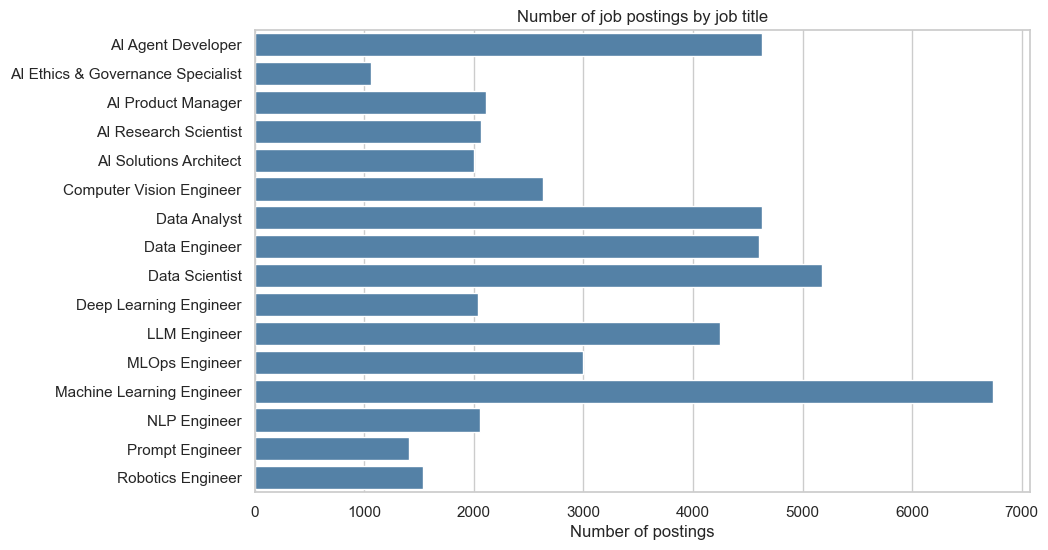

In [26]:
title_counts = df['job_title'].value_counts()
print(title_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=title_counts.values, y=title_counts.index, color='steelblue')
plt.title('Number of job postings by job title')
plt.xlabel('Number of postings'); plt.ylabel('')
plt.show()

**Insight:** Machine Learning Engineer is the most posted title (6,737 postings, 13.5%), followed by Data Scientist (10.4%), and AI Agent Developer and Data Analyst (9.3% each). The three generative-AI roles (LLM Engineer, AI Agent Developer, Prompt Engineer) together make up about 20.6% of all postings. AI Ethics & Governance Specialist is the rarest title (1,060 postings, about 2%).

#### Q2. Which countries post the most AI jobs?

United States           25.6
India                   10.6
United Kingdom           8.5
Canada                   6.7
Germany                  6.3
China                    5.3
United Arab Emirates     4.2
Netherlands              3.3
Australia                3.3
Singapore                3.2
Japan                    3.2
Saudi Arabia             3.1
South Korea              2.2
Israel                   2.2
Poland                   2.2
Ireland                  2.1
France                   2.1
Brazil                   2.1
Switzerland              2.1
Oman                     1.6
Name: company_location, dtype: float64


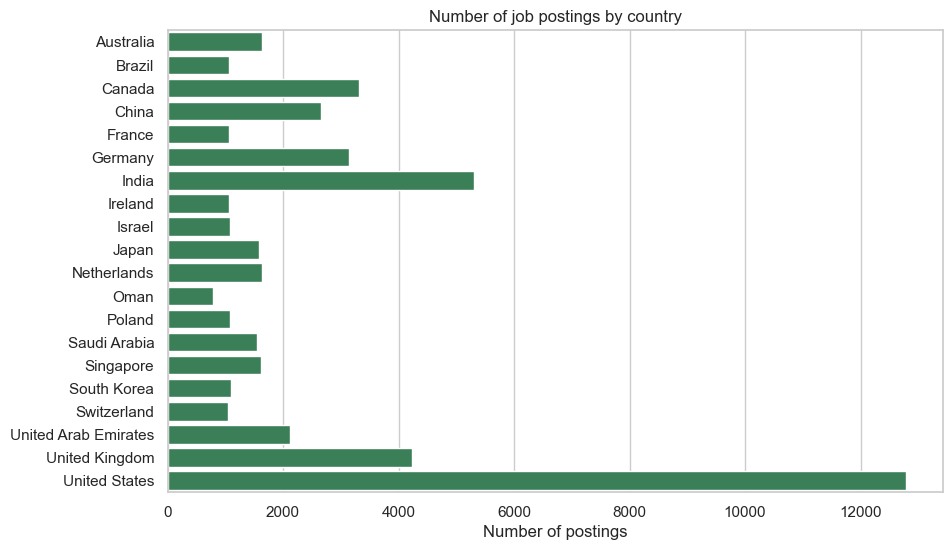

In [27]:
country_counts = df['company_location'].value_counts()
print((country_counts / len(df) * 100).round(1))

plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index, color='seagreen')
plt.title('Number of job postings by country')
plt.xlabel('Number of postings'); plt.ylabel('')
plt.show()

**Insight:** The United States alone posts about one job in four (25.6%). India (10.6%), the United Kingdom (8.5%), Canada (6.7%) and Germany (6.3%) follow, so the top five countries hold about 58% of all postings. Oman has the fewest (1.6%).

#### Q3. Which are the 15 most requested skills?

Python          60.1 % of postings
SQL             28.1 % of postings
PyTorch         24.0 % of postings
RAG             15.7 % of postings
AWS             13.1 % of postings
Statistics      13.1 % of postings
Scikit-learn    13.0 % of postings
Tableau         12.8 % of postings
LLM APIs        10.7 % of postings
Docker          10.5 % of postings
MLflow          10.4 % of postings
TensorFlow      10.3 % of postings
CUDA             9.2 % of postings
Airflow          8.7 % of postings
Azure            7.9 % of postings
dtype: object


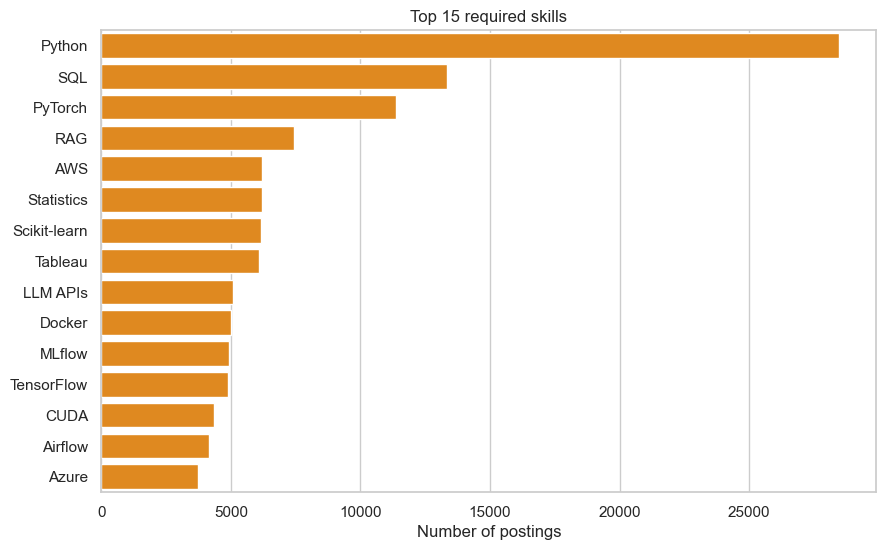

In [28]:
skill_counts = pd.Series(Counter(s for l in df['skills_list'] for s in l)).sort_values(ascending=False)
n_with_skills = (df['skills_list'].map(len) > 0).sum()
print((skill_counts.head(15) / n_with_skills * 100).round(1).astype(str) + ' % of postings')

plt.figure(figsize=(10, 6))
sns.barplot(x=skill_counts.head(15).values, y=skill_counts.head(15).index, color='darkorange')
plt.title('Top 15 required skills'); plt.xlabel('Number of postings'); plt.ylabel('')
plt.show()

**Insight:** Python is by far the most requested skill (about 60% of postings with a skills list), then SQL (28%) and PyTorch (24%). Newer generative-AI skills such as RAG (16%) and LLM APIs (11%) are already in the top 10, next to classic BI tools like Tableau (13%). About 5% of postings list no skills at all.

#### Q4. What is the profile of postings by experience level, employment type, company size and education?

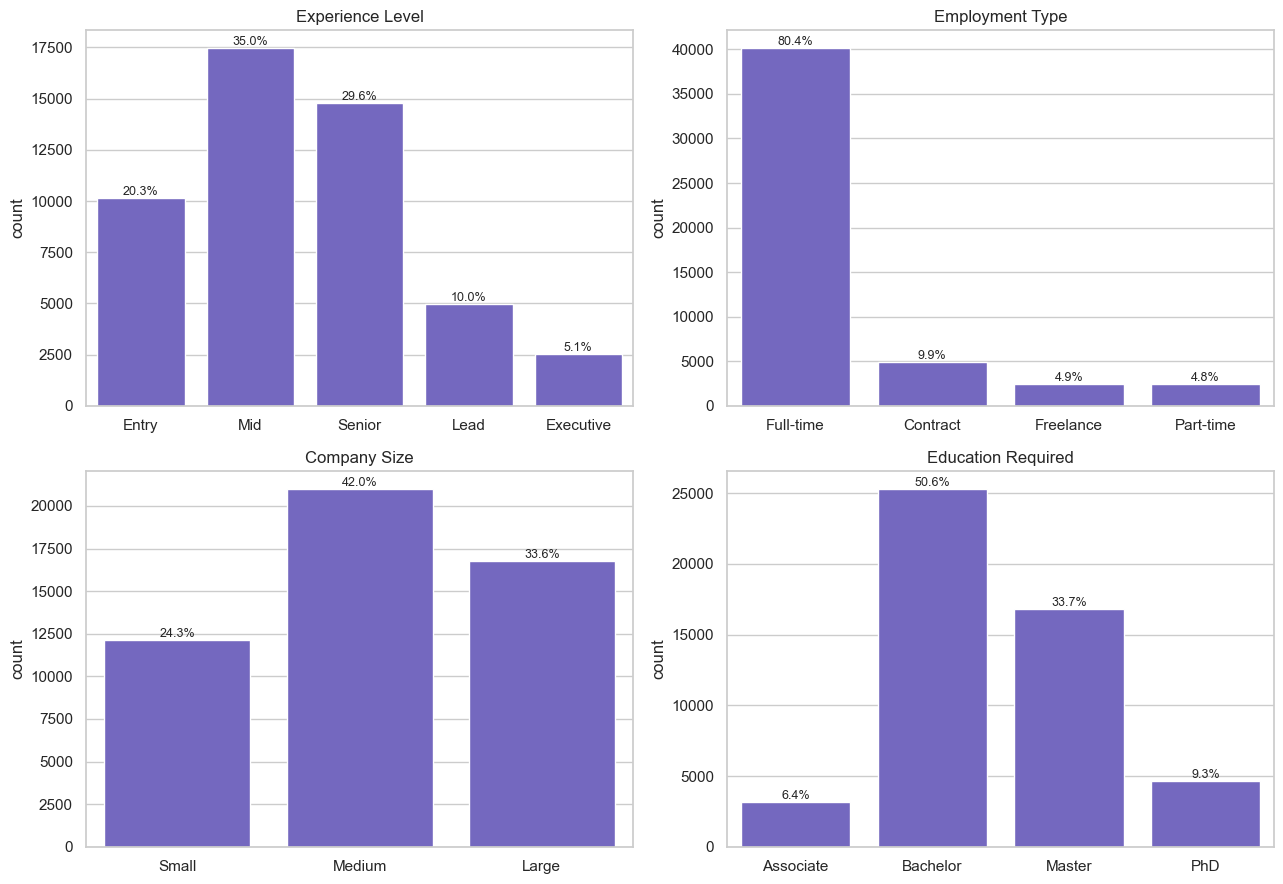

Remote ratio share (%):
0      42.6
50     33.3
100    24.1
Name: remote_ratio, dtype: float64


In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ['experience_level', 'employment_type', 'company_size', 'education_required']):
    order = df[col].cat.categories if df[col].cat.ordered else df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color='slateblue')
    ax.set_title(col.replace('_', ' ').title()); ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height() / len(df) * 100:.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()
print("Remote ratio share (%):")
print((df['remote_ratio'].value_counts(normalize=True).sort_index() * 100).round(1))

**Insight:** Mid-level (35%) and Senior (30%) roles dominate, while only 5% are Executive. Four in five postings are full-time. Medium companies post the most (42%). A Bachelor degree is the most common requirement (51%) and a PhD is rare (9%). Work mode is split 43% on-site, 33% hybrid and 24% fully remote.

#### Q5. What does the salary distribution look like?

count     49903.0
mean      85850.0
std       50662.0
min        4600.0
25%       49100.0
50%       77000.0
75%      112000.0
max      429200.0
Name: salary_usd, dtype: float64

Skewness: 1.21


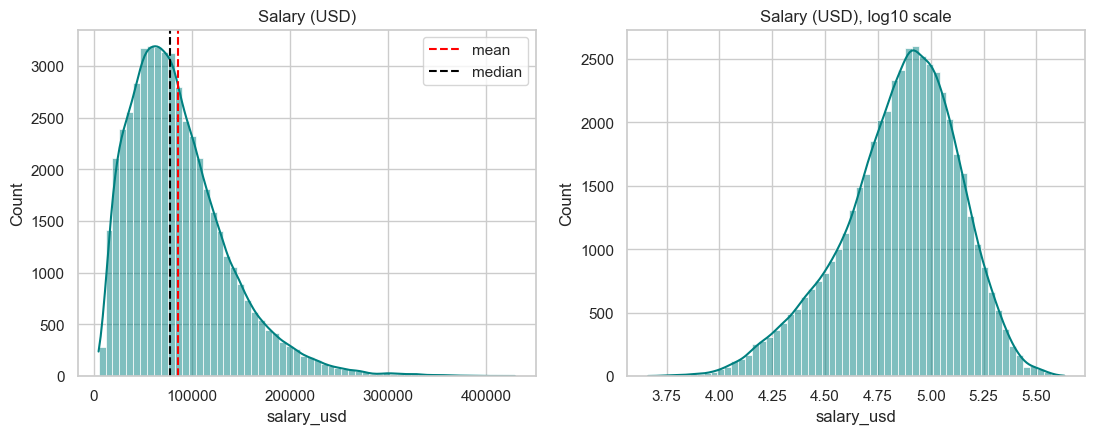

In [30]:
print(df['salary_usd'].describe().round(0))
print("\nSkewness:", round(df['salary_usd'].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['salary_usd'], bins=60, kde=True, ax=axes[0], color='teal')
axes[0].axvline(df['salary_usd'].mean(), color='red', ls='--', label='mean')
axes[0].axvline(df['salary_usd'].median(), color='black', ls='--', label='median')
axes[0].legend(); axes[0].set_title('Salary (USD)')
sns.histplot(np.log10(df['salary_usd']), bins=60, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Salary (USD), log10 scale')
plt.show()

**Insight:** Salary is right-skewed (skewness 1.21): the mean (about 85,850 USD) sits above the median (77,000 USD) because a small group of very high salaries pulls it up. Half of the postings pay between about 49,100 and 112,000 USD. On a log scale the distribution looks much closer to a bell shape, which is why the model in Q25 predicts `log_salary`.

#### Other numeric columns

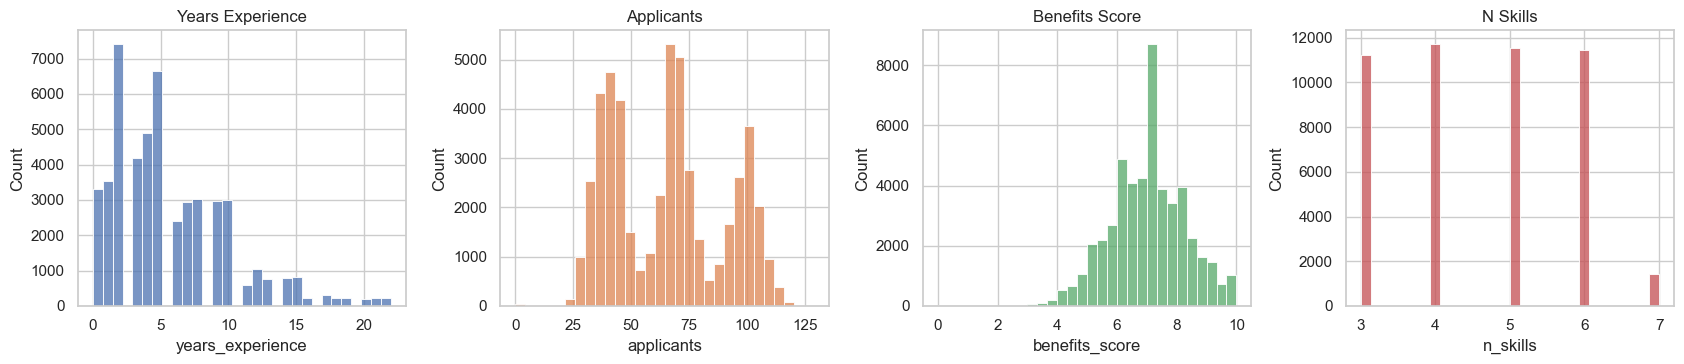

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, colr in zip(axes, ['years_experience', 'applicants', 'benefits_score', 'n_skills'], ['#4c72b0', '#dd8452', '#55a868', '#c44e52']):
    sns.histplot(df[col].dropna(), bins=30, ax=ax, color=colr)
    ax.set_title(col.replace('_', ' ').title())
plt.tight_layout()
plt.show()

**Insight:** Years of experience is right-skewed (most postings ask for under 10 years). Applicants shows several peaks, which come from the remote ratio (see Q17). Benefits score is centered near 7 and the number of skills is between 3 and 7.

### 5. Bivariate Analysis

Bivariate analysis compares **two variables** to find relationships. Our main target is `salary_usd`, so most comparisons use median salary, which is less affected by extreme values than the mean.

In [33]:
# helper: median salary by a category, with the number of postings
def salary_by(col, data=None, top=None):
    data = df if data is None else data
    g = data.groupby(col, observed=True)['salary_usd'].agg(['median', 'mean', 'count']).round(0)
    g = g.sort_values('median', ascending=False)
    return g.head(top) if top else g

#### Q6. How does salary change with experience level?

                    median      mean  count
experience_level                           
Entry              48600.0   49367.0  10137
Mid                72000.0   72665.0  17461
Senior             98300.0   99040.0  14794
Lead              125200.0  127190.0   4974
Executive         164300.0  164405.0   2537


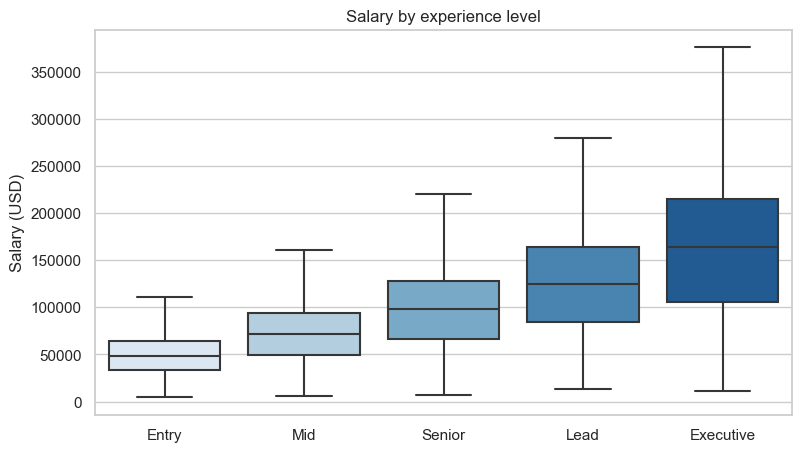

In [34]:
print(salary_by('experience_level').sort_index())
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='experience_level', y='salary_usd', palette='Blues', showfliers=False)
plt.title('Salary by experience level'); plt.xlabel(''); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Experience is a strong driver of pay. The median grows from 48,600 USD (Entry) to 72,000 (Mid), 98,300 (Senior), 125,200 (Lead) and 164,300 (Executive). An Executive earns about 3.4 times an Entry-level worker, and each step up adds roughly 27% to 48%.

#### Q7. Which job titles pay the most?

                                    median      mean  count
job_title                                                  
AI Research Scientist              93300.0  104071.0   2068
LLM Engineer                       91400.0  101555.0   4243
AI Solutions Architect             90100.0   99391.0   1997
AI Agent Developer                 86400.0   95466.0   4632
Deep Learning Engineer             86400.0   94082.0   2037
AI Product Manager                 85950.0   94522.0   2106
Computer Vision Engineer           81750.0   89233.0   2630
NLP Engineer                       79600.0   89255.0   2055
Machine Learning Engineer          79400.0   87385.0   6737
MLOps Engineer                     78500.0   86459.0   2997
Robotics Engineer                  77150.0   85471.0   1536
Data Scientist                     74500.0   81638.0   5173
Data Engineer                      71000.0   78457.0   4599
AI Ethics & Governance Specialist  70050.0   74023.0   1060
Prompt Engineer                    62100

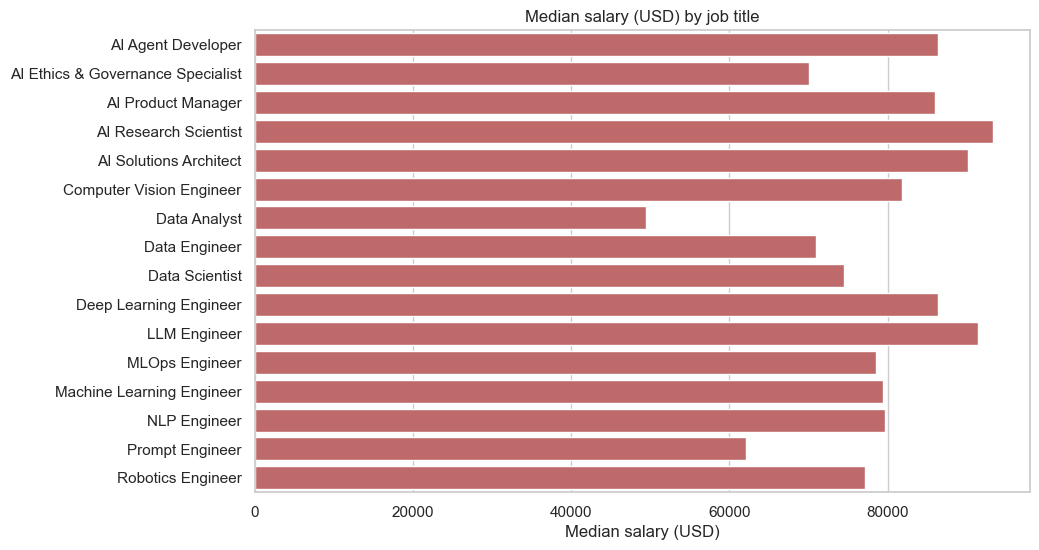

In [35]:
t = salary_by('job_title')
print(t)
plt.figure(figsize=(10, 6))
sns.barplot(x=t['median'], y=t.index, color='indianred')
plt.title('Median salary (USD) by job title'); plt.xlabel('Median salary (USD)'); plt.ylabel('')
plt.show()

**Insight:** AI Research Scientist (93,300 USD), LLM Engineer (91,400) and AI Solutions Architect (90,100) have the highest median pay. Data Analyst (49,500) and Prompt Engineer (62,100) pay the least, so the best-paid title earns almost twice the lowest. Grouped by family, Strategy & Research (86,200) and Generative AI (84,250) pay more than ML Engineering (80,100) and Data (64,200).

#### Q8. Which countries pay the most?

                        median      mean  count
company_location                               
United States         110300.0  119918.0  12782
Switzerland           105600.0  116871.0   1049
Singapore              92700.0   99114.0   1615
Israel                 88500.0   97226.0   1082
United Arab Emirates   87200.0   95384.0   2119
Canada                 84050.0   92204.0   3322
Australia              83250.0   90597.0   1640
United Kingdom         81100.0   88327.0   4238
Saudi Arabia           79100.0   85598.0   1556
Germany                78700.0   85640.0   3142
Ireland                77900.0   85310.0   1071
Netherlands            76000.0   82158.0   1643
France                 69300.0   74897.0   1067
Japan                  64600.0   71404.0   1585
South Korea            62300.0   67500.0   1095
Oman                   60200.0   66564.0    785
China                  50250.0   55014.0   2654
Poland                 46500.0   49269.0   1079
Brazil                 36550.0   39320.0

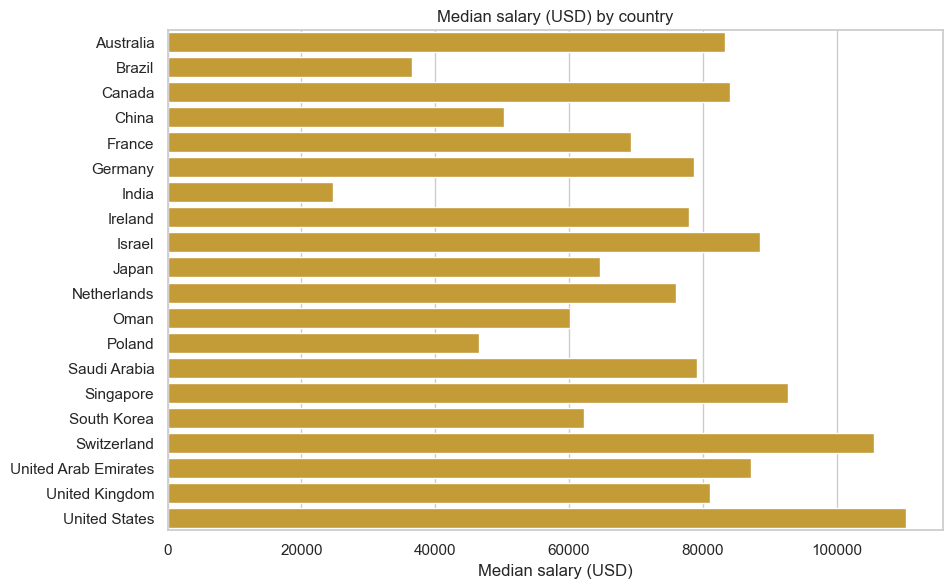

In [36]:
t = salary_by('company_location')
print(t)
plt.figure(figsize=(10, 6.5))
sns.barplot(x=t['median'], y=t.index, color='goldenrod')
plt.title('Median salary (USD) by country'); plt.xlabel('Median salary (USD)'); plt.ylabel('')
plt.show()

**Insight:** Location matters a lot. The United States (110,300 USD) and Switzerland (105,600) pay the most, then Singapore (92,700). India (24,700), Brazil (36,550) and Poland (46,500) pay the least, so a US posting pays about 4.5 times an Indian one. These are nominal USD values at fixed exchange rates, not adjusted for cost of living.

#### Q9. Does a higher education requirement lead to a higher salary?

                     median     mean  count
education_required                         
Associate           75000.0  85249.0   3176
Bachelor            76400.0  85253.0  25263
Master              77600.0  86448.0  16812
PhD                 79100.0  87344.0   4652


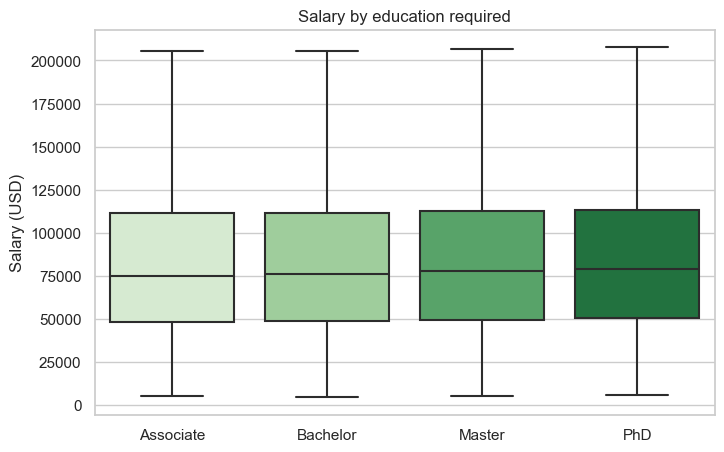

In [37]:
print(salary_by('education_required').sort_index())
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='education_required', y='salary_usd', palette='Greens', showfliers=False)
plt.title('Salary by education required'); plt.xlabel(''); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Education has only a small link to pay. The median goes from 75,000 USD (Associate) to 76,400 (Bachelor), 77,600 (Master) and 79,100 (PhD), a gap of only about 5% between the lowest and highest level.

#### Q10. Which industries pay the most?

                     median     mean  count
industry                                   
Finance             88100.0  99067.0   3554
Technology          85500.0  93962.0   3410
Consulting          81600.0  92015.0   3438
Automotive          80150.0  89652.0   3466
Healthcare          79900.0  89221.0   3425
Gaming              79900.0  88665.0   3444
Energy              79900.0  88909.0   5147
Telecommunications  76500.0  84232.0   3510
Media               75500.0  84372.0   3454
Manufacturing       74700.0  82794.0   3416
Logistics           74500.0  82285.0   3356
Retail              73200.0  81082.0   3437
Government          66000.0  73120.0   3383
Education           63100.0  70443.0   3463


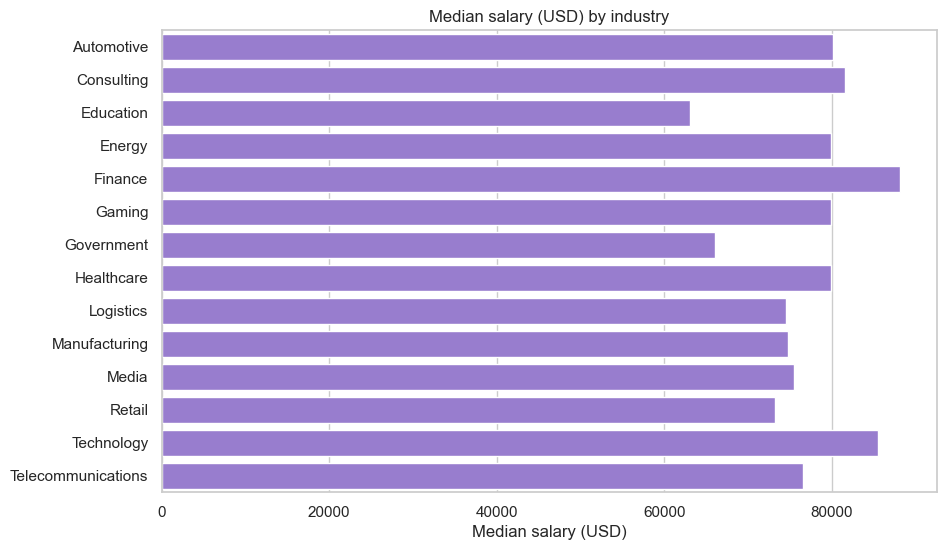

In [38]:
t = salary_by('industry')
print(t)
plt.figure(figsize=(10, 6))
sns.barplot(x=t['median'], y=t.index, color='mediumpurple')
plt.title('Median salary (USD) by industry'); plt.xlabel('Median salary (USD)'); plt.ylabel('')
plt.show()

**Insight:** Finance (88,100 USD), Technology (85,500) and Consulting (81,600) pay the most. Education (63,100) and Government (66,000) pay the least, about 30% below Finance.

#### Q11. Does company size affect salary?

               median     mean  count
company_size                         
Small         68600.0  76211.0  12134
Medium        76800.0  85428.0  20980
Large         83700.0  93344.0  16789


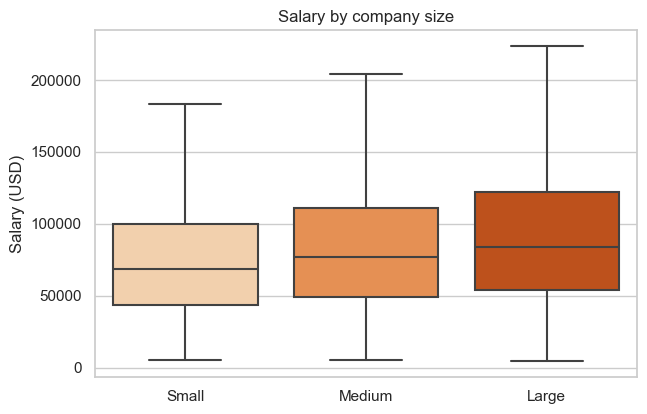

In [39]:
print(salary_by('company_size').sort_index())
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='company_size', y='salary_usd', palette='Oranges', showfliers=False)
plt.title('Salary by company size'); plt.xlabel(''); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Bigger companies pay more: median 68,600 USD (Small), 76,800 (Medium) and 83,700 (Large). A Large company pays about 22% more than a Small one.

#### Q12. Does remote work change the salary?

               median     mean  count
remote_ratio                         
0             76600.0  85338.0  21253
50            76700.0  85370.0  16634
100           78100.0  87419.0  12016


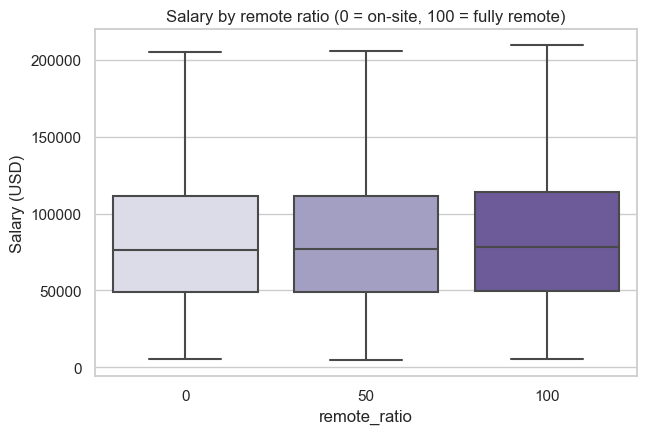

In [40]:
print(salary_by('remote_ratio').sort_index())
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='remote_ratio', y='salary_usd', palette='Purples', showfliers=False)
plt.title('Salary by remote ratio (0 = on-site, 100 = fully remote)'); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Remote work does not change pay in this data. The median is 76,600 USD for on-site, 76,700 for hybrid and 78,100 for fully remote jobs, a difference of about 2%.

#### Q13. How does employment type relate to salary?

                  median     mean  count
employment_type                         
Contract         83000.0  92935.0   4945
Full-time        79400.0  88124.0  40119
Freelance        63700.0  70924.0   2447
Part-time        43500.0  48327.0   2392


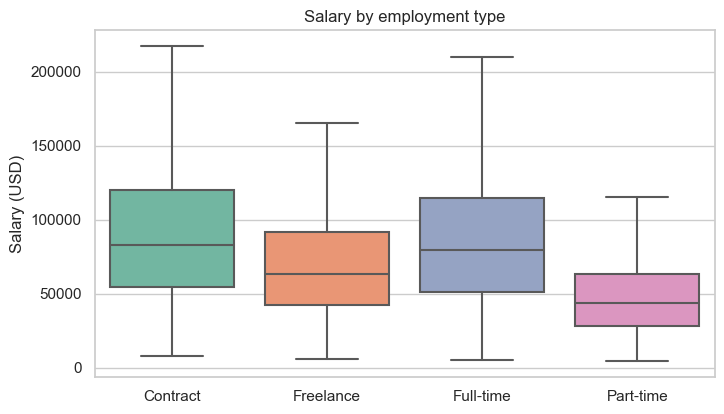

In [41]:
print(salary_by('employment_type'))
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x='employment_type', y='salary_usd', palette='Set2', showfliers=False)
plt.title('Salary by employment type'); plt.xlabel(''); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Contract roles have the highest median (83,000 USD), slightly above full-time (79,400). Freelance (63,700) and especially part-time (43,500, about 45% below full-time) pay much less. The data does not say how many hours each posting covers, so part-time pay may be a pro-rata figure.

#### Q14. How strongly are years of experience and salary correlated?

Pearson correlation : 0.561
Spearman correlation: 0.518

Correlation inside each experience level:
experience_level
Entry        0.13
Mid          0.02
Senior       0.03
Lead         0.05
Executive    0.20
dtype: float64


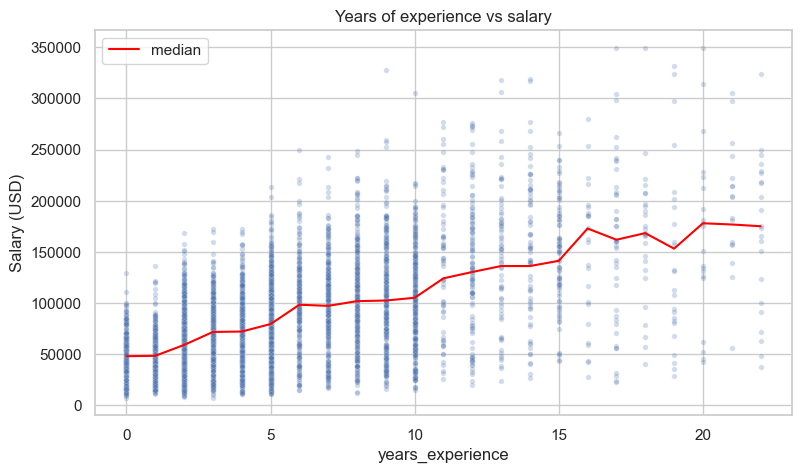

In [42]:
r_p = df['years_experience'].corr(df['salary_usd'])
r_s = df['years_experience'].corr(df['salary_usd'], method='spearman')
print(f"Pearson correlation : {r_p:.3f}\nSpearman correlation: {r_s:.3f}")
print("\nCorrelation inside each experience level:")
print(df.groupby('experience_level', observed=True).apply(lambda g: g['years_experience'].corr(g['salary_usd'])).round(2))

plt.figure(figsize=(9, 5))
sample = df.sample(5000, random_state=1)
sns.scatterplot(data=sample, x='years_experience', y='salary_usd', alpha=0.25, s=15)
sns.lineplot(data=df, x='years_experience', y='salary_usd', estimator='median', errorbar=None, color='red', label='median')
plt.title('Years of experience vs salary'); plt.ylabel('Salary (USD)')
plt.show()

**Insight:** Years of experience and salary have a moderate positive correlation (Pearson 0.56). But inside each experience level the correlation is weak (0.02 to 0.20), so the link comes mostly from the *level* label (Entry, Mid, Senior ...) and not from the exact number of years.

#### Q15. Do better benefits go with a higher salary?

Correlation benefits_score vs salary: -0.003
                median  count
_benefit_band                
<=5            77500.0   3177
5-6            76900.0   7709
6-7            77100.0  16529
7-8            77000.0  12610
8-9            76500.0   7136
9-10           77200.0   2742


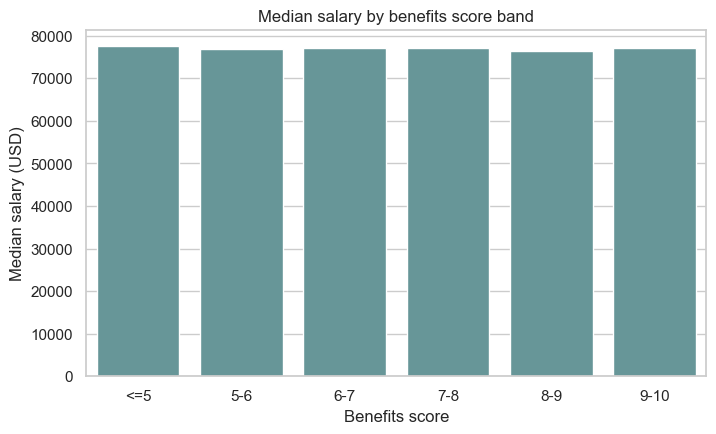

In [43]:
print("Correlation benefits_score vs salary:", round(df['benefits_score'].corr(df['salary_usd']), 3))
df['_benefit_band'] = pd.cut(df['benefits_score'], [-0.1, 5, 6, 7, 8, 9, 10], labels=['<=5', '5-6', '6-7', '7-8', '8-9', '9-10'])
print(df.groupby('_benefit_band', observed=True)['salary_usd'].agg(['median', 'count']).round(0))

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df, x='_benefit_band', y='salary_usd', estimator='median', errorbar=None, color='cadetblue')
plt.title('Median salary by benefits score band'); plt.xlabel('Benefits score'); plt.ylabel('Median salary (USD)')
plt.show()
df = df.drop(columns='_benefit_band')

**Insight:** The benefits score has no relation with salary (correlation -0.003), and the median pay is almost flat across all score bands (76,500 to 77,500 USD). Good benefits are not a sign of a high salary in these postings.

#### Q16. Which skills are linked to the highest salary?

We look at the median salary of postings that ask for each skill. Because skills are not independent of seniority, this shows association, not cause.

Overall median salary: 77000.0
                         median  count  vs overall %               main role  share of main role
skills_list                                                                                     
JAX                     92950.0   1266          20.7   AI Research Scientist                0.99
Vector Databases        92700.0   2276          20.4            LLM Engineer                0.99
Mathematics             92700.0   1289          20.4   AI Research Scientist                0.99
Reinforcement Learning  92400.0   1301          20.0   AI Research Scientist                0.99
Fine-tuning             92300.0   2278          19.9            LLM Engineer                0.99
GCP                     91500.0   1242          18.8  AI Solutions Architect                0.99
System Design           91350.0   1236          18.6  AI Solutions Architect                0.99
LangChain               90700.0   2283          17.8            LLM Engineer                0.99

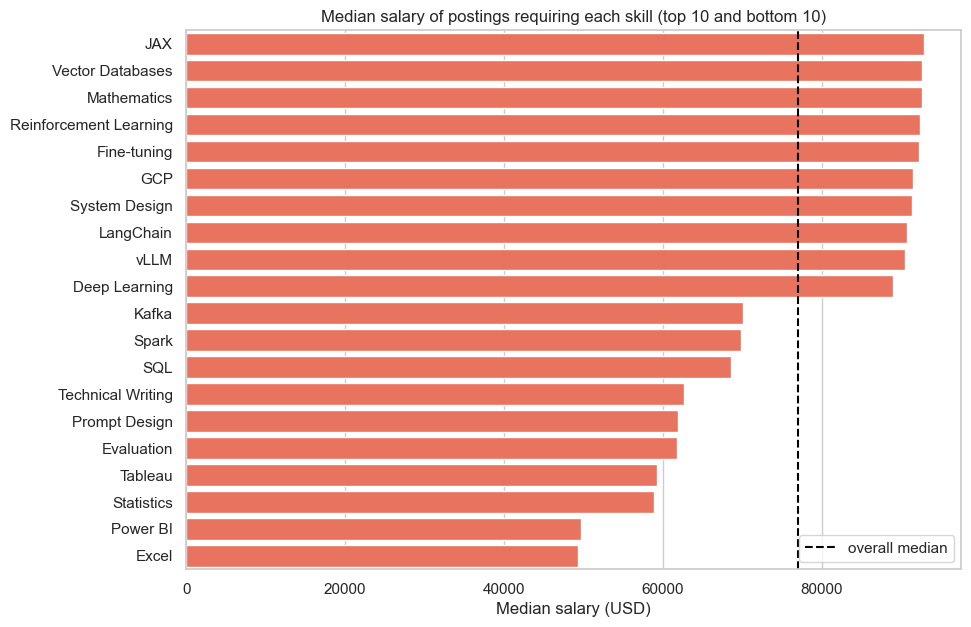

In [44]:
sk = df[df['skills_list'].map(len) > 0][['skills_list', 'salary_usd', 'experience_level']].explode('skills_list')
overall_median = df['salary_usd'].median()
sk_stats = sk.groupby('skills_list')['salary_usd'].agg(['median', 'count'])
sk_stats = sk_stats[sk_stats['count'] >= 500].sort_values('median', ascending=False)
sk_stats['vs overall %'] = ((sk_stats['median'] / overall_median - 1) * 100).round(1)
# which job title asks for each skill most often? (a skill can simply stand for a role)
main_role = sk.merge(df[['job_title']], left_index=True, right_index=True).groupby('skills_list')['job_title'].agg(
    lambda t: t.value_counts().index[0])
main_share = sk.merge(df[['job_title']], left_index=True, right_index=True).groupby('skills_list')['job_title'].agg(
    lambda t: t.value_counts(normalize=True).iloc[0])
sk_stats['main role'] = main_role
sk_stats['share of main role'] = main_share.round(2)
print("Overall median salary:", overall_median)
print(sk_stats.head(10)); print("..."); print(sk_stats.tail(5))

top = pd.concat([sk_stats.head(10), sk_stats.tail(10)])
plt.figure(figsize=(10, 7))
sns.barplot(x=top['median'], y=top.index, color='tomato')
plt.axvline(overall_median, color='black', ls='--', label='overall median'); plt.legend()
plt.title('Median salary of postings requiring each skill (top 10 and bottom 10)'); plt.xlabel('Median salary (USD)'); plt.ylabel('')
plt.show()

**Insight:** Postings that ask for JAX, Mathematics, Vector Databases, Reinforcement Learning or Fine-tuning pay about 20% above the overall median, while Excel and Power BI postings pay about 36% below it. **Be careful:** the last two columns show that these skills mostly identify a role. About 99% of the Excel and Power BI postings are Data Analyst jobs, 99% of JAX postings are AI Research Scientist jobs, and 99% of Vector Databases postings are LLM Engineer jobs. So the table really shows the pay of *roles*, not the pay value of a single skill.

#### Q17. Which roles are the most competitive, and does remote work attract more applicants?

job_title
MLOps Engineer                       66.4
Prompt Engineer                      66.2
AI Product Manager                   66.0
Data Scientist                       65.8
AI Research Scientist                65.7
AI Solutions Architect               65.7
NLP Engineer                         65.7
AI Ethics & Governance Specialist    65.6
Data Analyst                         65.6
LLM Engineer                         65.4
Data Engineer                        65.4
Deep Learning Engineer               65.4
Machine Learning Engineer            65.3
Robotics Engineer                    65.3
Computer Vision Engineer             65.1
AI Agent Developer                   64.7
Name: applicants, dtype: float64

Average applicants by remote ratio:
remote_ratio
0      43.4
50     69.8
100    98.7
Name: applicants, dtype: float64


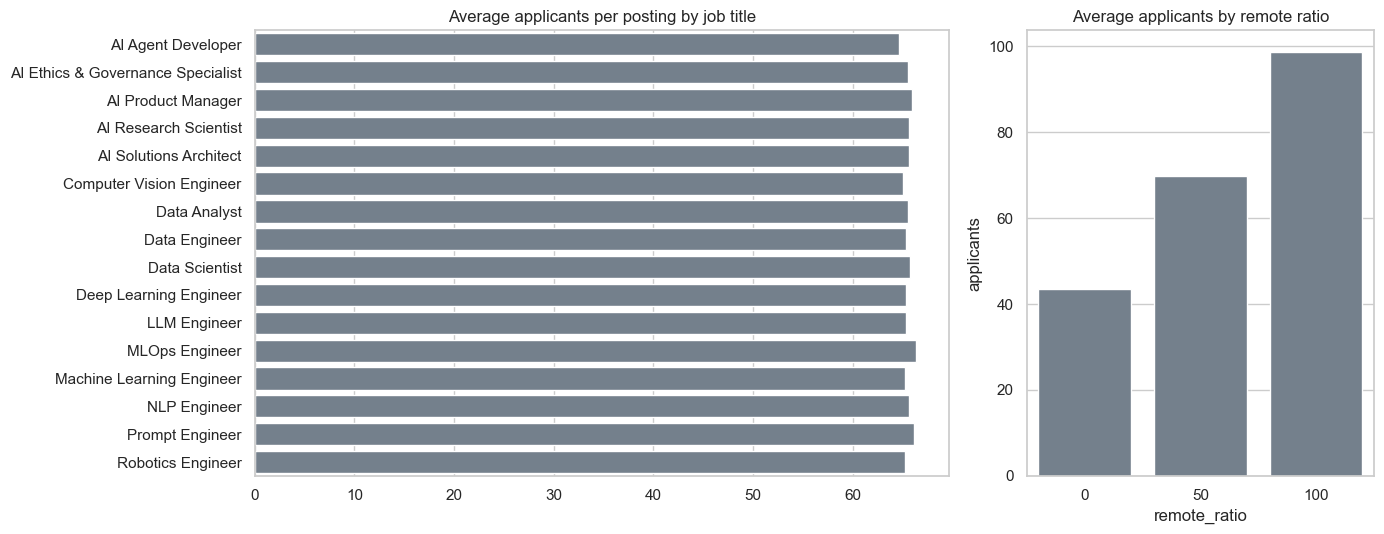

In [45]:
app_title = df.groupby('job_title', observed=True)['applicants'].mean().sort_values(ascending=False).round(1)
print(app_title)
print("\nAverage applicants by remote ratio:")
print(df.groupby('remote_ratio')['applicants'].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(x=app_title.values, y=app_title.index, color='slategray', ax=axes[0])
axes[0].set_title('Average applicants per posting by job title'); axes[0].set_ylabel('')
sns.barplot(data=df, x='remote_ratio', y='applicants', errorbar=None, color='slategray', ax=axes[1])
axes[1].set_title('Average applicants by remote ratio')
plt.tight_layout()
plt.show()

**Insight:** The role has almost no effect on competition (all titles receive 65 to 66 applicants on average). Work mode does: on-site jobs get about 43 applicants, hybrid about 70 and fully remote about 99, so remote postings attract 2.3 times more applicants for the same pay (Q12).

### 6. Multivariate Analysis

Multivariate analysis studies **three or more variables together**. It shows whether a pattern from the bivariate step still holds once a second factor is taken into account.

#### Q18. How does median salary vary by job title and experience level together?

experience_level                     Entry      Mid    Senior      Lead  Executive
job_title                                                                         
AI Research Scientist              62000.0  90300.0  121200.0  154900.0   192550.0
AI Solutions Architect             57900.0  86900.0  112650.0  148500.0   202000.0
LLM Engineer                       59200.0  87000.0  116300.0  151300.0   193600.0
AI Agent Developer                 54100.0  81700.0  113750.0  143550.0   198700.0
Deep Learning Engineer             53100.0  78100.0  106800.0  137700.0   188400.0
NLP Engineer                       52800.0  75200.0  105950.0  141150.0   182450.0
AI Product Manager                 51900.0  78100.0  109400.0  135200.0   175200.0
Computer Vision Engineer           51900.0  76150.0  106100.0  130300.0   174500.0
Machine Learning Engineer          50900.0  75000.0   99600.0  131600.0   170100.0
MLOps Engineer                     49650.0  71850.0  101100.0  124800.0   171800.0
Robo

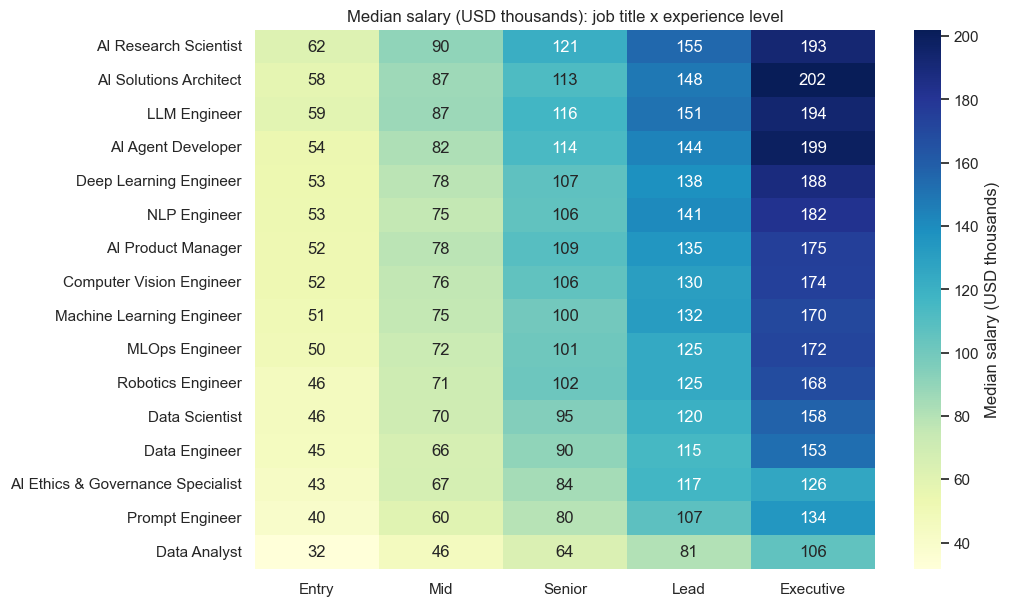

In [46]:
pivot = df.pivot_table(index='job_title', columns='experience_level', values='salary_usd', aggfunc='median', observed=True)
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
print(pivot.round(0))

plt.figure(figsize=(10, 7))
sns.heatmap(pivot / 1000, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Median salary (USD thousands)'})
plt.title('Median salary (USD thousands): job title x experience level'); plt.xlabel(''); plt.ylabel('')
plt.show()

**Insight:** The ranking of roles is stable at every level: Data Analyst is lowest and AI Research Scientist / AI Solutions Architect are near the top. Level changes pay more than role does. For example, an Executive Data Analyst (106,150 USD) earns more than a Mid-level Machine Learning Engineer (75,000), and a Senior AI Research Scientist (121,200) earns about the same as a Lead Data Scientist (120,250).

#### Q19. Is there a salary premium for a PhD or Master's degree at the same experience level?

education_required  Associate  Bachelor    Master       PhD
experience_level                                           
Entry                 48300.0   48200.0   49150.0   49000.0
Mid                   69050.0   71600.0   72300.0   75400.0
Senior                98900.0   97600.0   98600.0  101000.0
Lead                 127400.0  124200.0  127450.0  125500.0
Executive            167900.0  163300.0  165100.0  158900.0

Premium over a Bachelor degree (%):
education_required  Associate  Bachelor  Master  PhD
experience_level                                    
Entry                     0.2       0.0     2.0  1.7
Mid                      -3.6       0.0     1.0  5.3
Senior                    1.3       0.0     1.0  3.5
Lead                      2.6       0.0     2.6  1.0
Executive                 2.8       0.0     1.1 -2.7


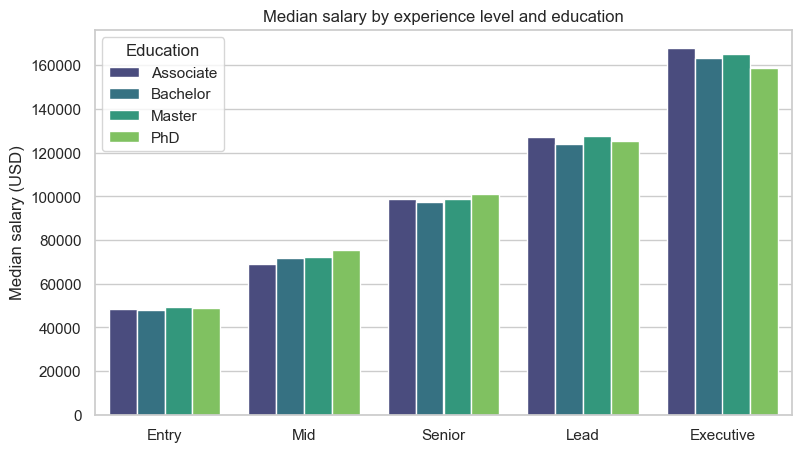

In [47]:
edu_exp = df.pivot_table(index='experience_level', columns='education_required', values='salary_usd', aggfunc='median', observed=True)
print(edu_exp.round(0))
print("\nPremium over a Bachelor degree (%):")
print((edu_exp.div(edu_exp['Bachelor'], axis=0).sub(1).mul(100)).round(1))

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='experience_level', y='salary_usd', hue='education_required', estimator='median', errorbar=None, palette='viridis')
plt.title('Median salary by experience level and education'); plt.xlabel(''); plt.ylabel('Median salary (USD)')
plt.legend(title='Education')
plt.show()

**Insight:** Inside the same experience level, extra education adds very little. A PhD earns at most +5.3% over a Bachelor degree (Mid level), a Master about +1% to +2.6%, and at Executive level the PhD is even 2.7% lower. Experience level explains pay much better than degree.

#### Q20. Which industries hire for which roles?

job_title           AI Agent Developer  AI Ethics & Governance Specialist  AI Product Manager  AI Research Scientist  AI Solutions Architect  Computer Vision Engineer  Data Analyst  Data Engineer  \
industry                                                                                                                                                                                              
Automotive                         9.0                                2.1                 4.4                    4.1                     3.9                       5.4           9.4            9.5   
Consulting                         8.8                                2.2                 4.4                    3.9                     4.4                       5.2           8.4            9.6   
Education                          9.7                                2.7                 4.7                    4.1                     3.4                       5.4           9.6            8.7   
Energ

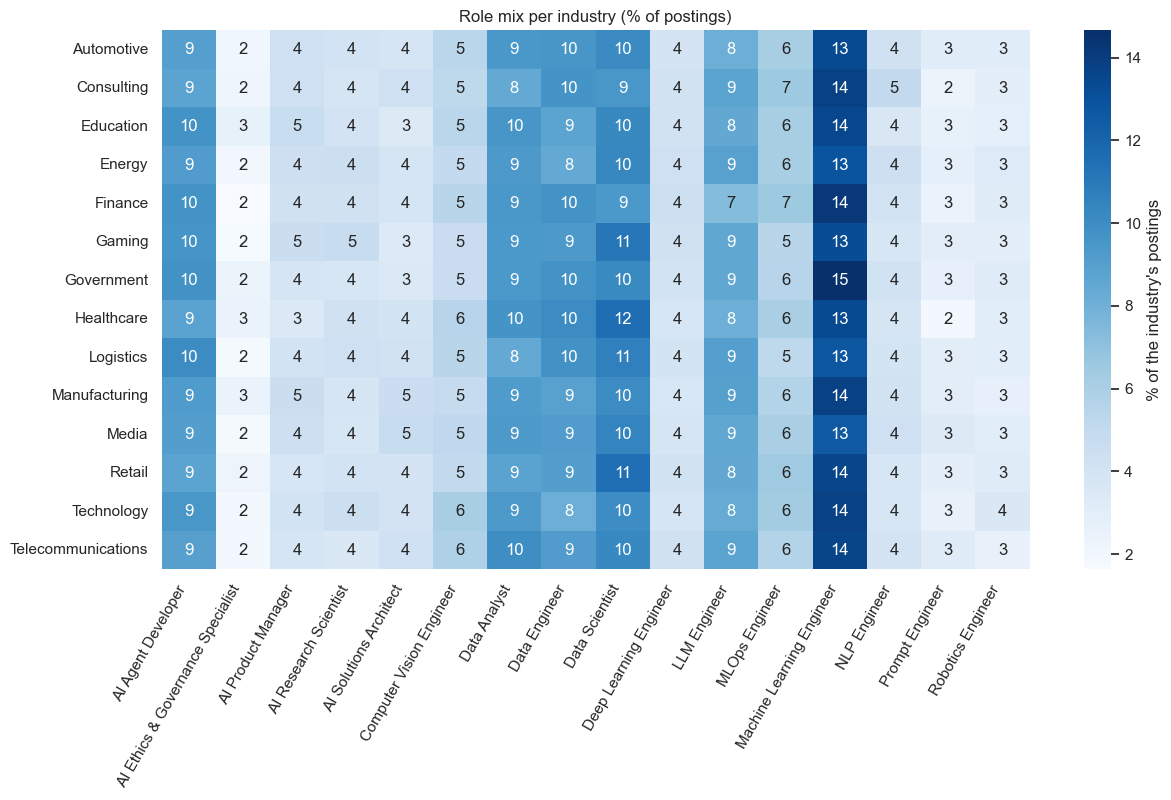

In [48]:
mix = pd.crosstab(df['industry'], df['job_title'], normalize='index') * 100
print(mix.round(1))

plt.figure(figsize=(14, 7))
sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of the industry\'s postings'})
plt.title('Role mix per industry (% of postings)'); plt.xlabel(''); plt.ylabel('')
plt.xticks(rotation=60, ha='right')
plt.show()

**Insight:** Every industry hires almost the same mix of roles. For any given role, its share of postings differs by at most about 2 percentage points between industries (for example, Machine Learning Engineer is about 13.5% everywhere). Industry changes **how much** a role pays (Q10), not **which roles** are hired.

#### Q21. How are all numeric variables correlated with each other?

                  salary_usd  years_experience  remote_ratio  applicants  benefits_score  n_skills
salary_usd             1.000             0.561         0.015       0.011          -0.003    -0.001
years_experience       0.561             1.000         0.002      -0.000           0.004     0.007
remote_ratio           0.015             0.002         1.000       0.898           0.007     0.000
applicants             0.011            -0.000         0.898       1.000           0.007    -0.000
benefits_score        -0.003             0.004         0.007       0.007           1.000    -0.001
n_skills              -0.001             0.007         0.000      -0.000          -0.001     1.000


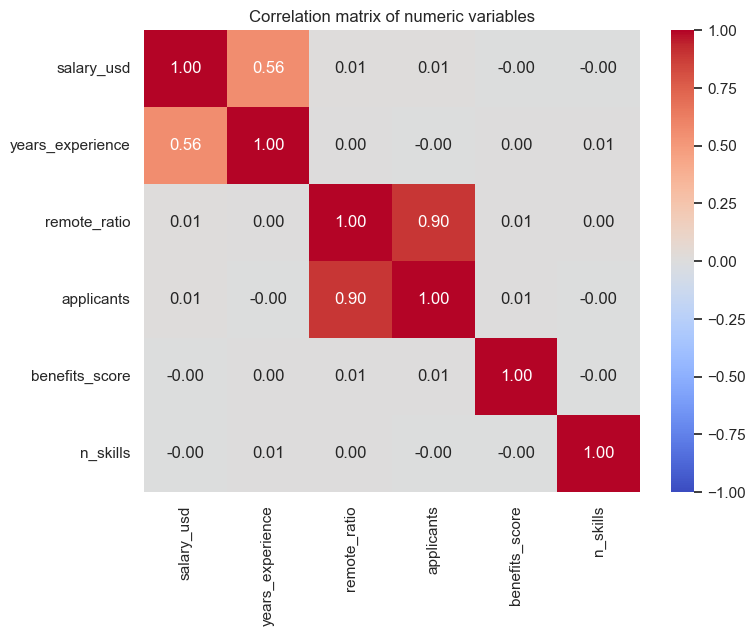

In [49]:
num = df[['salary_usd', 'years_experience', 'remote_ratio', 'applicants', 'benefits_score', 'n_skills']]
corr = num.corr()
print(corr.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix of numeric variables')
plt.show()

**Insight:** Salary is related only to years of experience (0.56). Remote ratio and applicants are strongly correlated with each other (0.90), which matches Q17. Benefits score, number of skills and applicants have no correlation with salary (all between -0.01 and 0.02), and no other pair of variables is correlated.

### 7. Feature Engineering

Feature engineering creates new columns that make patterns easier to see or easier for a model to use.

| New feature | How it is built | Why it is useful |
|---|---|---|
| `posting_month`, `posting_quarter`, `posting_weekday` | from `posting_date` | seasonality |
| `days_to_deadline` | deadline - posting date | length of the hiring window |
| `seniority_group` | Entry/Mid vs Senior/Lead/Executive | simple 2-group view |
| `work_mode` | remote ratio 0 / 50 / 100 -> On-site / Hybrid / Remote | readable label |
| `role_family` | groups the 16 titles into 4 families | fewer, clearer groups |
| `salary_band` | salary quartiles | Low / Medium / High / Very High |
| `salary_index` | salary / median salary of the same country | pay compared with the local market |
| `log_salary` | log of salary | reduces the right skew |
| `skill_*` flags | 1 if the posting asks for a top-15 skill | model-ready skill columns |
| `*_code` columns | numeric codes of the categories | encoded categorical variables |

In [50]:
# --- date features ---
df['posting_month'] = df['posting_date'].dt.to_period('M')
df['posting_quarter'] = df['posting_date'].dt.to_period('Q')
df['posting_weekday'] = df['posting_date'].dt.day_name()
df['days_to_deadline'] = (df['application_deadline'] - df['posting_date']).dt.days

# --- group / label features ---
df['seniority_group'] = np.where(df['experience_level'].isin(['Entry', 'Mid']), 'Entry/Mid', 'Senior+')
df['work_mode'] = df['remote_ratio'].map({0: 'On-site', 50: 'Hybrid', 100: 'Remote'})
families = {
 'Data Analyst':'Data', 'Data Engineer':'Data', 'Data Scientist':'Data',
 'Machine Learning Engineer':'ML Engineering', 'MLOps Engineer':'ML Engineering', 'Deep Learning Engineer':'ML Engineering',
 'Computer Vision Engineer':'ML Engineering', 'NLP Engineer':'ML Engineering', 'Robotics Engineer':'ML Engineering',
 'LLM Engineer':'Generative AI', 'AI Agent Developer':'Generative AI', 'Prompt Engineer':'Generative AI',
 'AI Product Manager':'Strategy & Research', 'AI Solutions Architect':'Strategy & Research',
 'AI Ethics & Governance Specialist':'Strategy & Research', 'AI Research Scientist':'Strategy & Research'}
df['role_family'] = df['job_title'].astype(str).map(families)

# --- salary features ---
df['salary_band'] = pd.qcut(df['salary_usd'], 4, labels=['Low', 'Medium', 'High', 'Very High'])
df['salary_index'] = df['salary_usd'] / df.groupby('company_location', observed=True)['salary_usd'].transform('median')
df['log_salary'] = np.log(df['salary_usd'])

# --- skill flags for the 15 most common skills ---
top_skills = skill_counts.head(15).index.tolist()
for s in top_skills:
    df['skill_' + re.sub(r'\W+', '_', s.lower()).strip('_')] = df['skills_list'].map(lambda l: int(s in l))

# --- encoded categorical variables ---
for c in ['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'education_required']:
    df[c + '_code'] = df[c].cat.codes

new_cols = ['posting_month', 'days_to_deadline', 'seniority_group', 'work_mode', 'role_family', 'salary_band', 'salary_index', 'log_salary']
print(df[new_cols].head(8))
print("\nShape now:", df.shape)

  posting_month  days_to_deadline seniority_group work_mode     role_family salary_band  salary_index  log_salary
0       2026-08              38.0         Senior+    Hybrid  ML Engineering        High      1.043578   11.418615
1       2025-11              46.0         Senior+    Hybrid   Generative AI   Very High      2.203453   12.093464
2       2025-11              57.0         Senior+   On-site   Generative AI   Very High      1.389428   11.766016
3       2026-02              38.0         Senior+   On-site   Generative AI         Low      0.554113   10.555813
4       2026-08              28.0       Entry/Mid   On-site  ML Engineering      Medium      0.884094   11.180246
5       2026-02              37.0       Entry/Mid   On-site   Generative AI      Medium      0.733249   10.968198
6       2026-08               NaN       Entry/Mid    Remote   Generative AI         Low      0.548684   10.638256
7       2026-01              26.0       Entry/Mid    Hybrid            Data      Medium 

#### Q22. Do senior jobs ask for more skills?

                  mean  median  count
experience_level                     
Entry             4.58     5.0   9656
Mid               4.57     5.0  16592
Senior            4.58     5.0  14016
Lead              4.57     5.0   4728
Executive         4.63     5.0   2418

By role family:
role_family
Data                   4.69
Generative AI          4.49
ML Engineering         4.58
Strategy & Research    4.49
Name: n_skills, dtype: float64


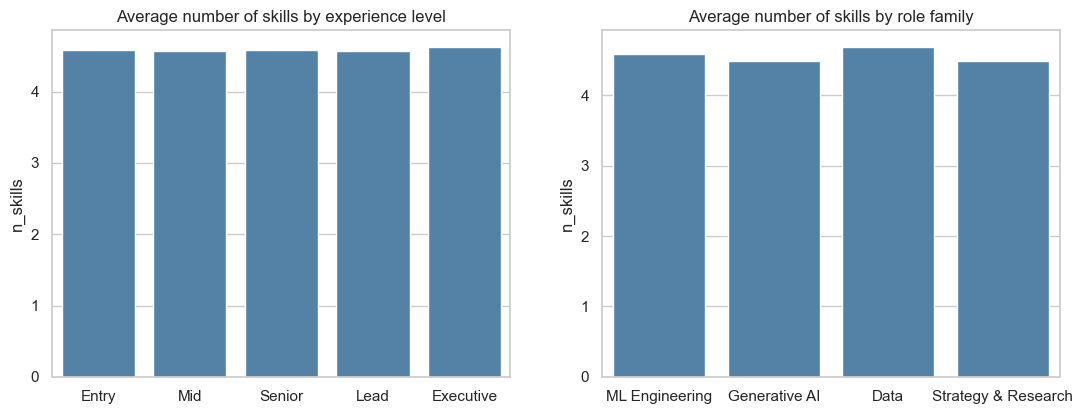

In [51]:
print(df.groupby('experience_level', observed=True)['n_skills'].agg(['mean', 'median', 'count']).round(2))
print("\nBy role family:")
print(df.groupby('role_family')['n_skills'].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x='experience_level', y='n_skills', errorbar=None, color='steelblue', ax=axes[0])
axes[0].set_title('Average number of skills by experience level'); axes[0].set_xlabel('')
sns.barplot(data=df, x='role_family', y='n_skills', errorbar=None, color='steelblue', ax=axes[1])
axes[1].set_title('Average number of skills by role family'); axes[1].set_xlabel('')
plt.show()

**Insight:** Senior roles do not ask for more skills. The average is about 4.6 skills at every level (4.57 to 4.63), and all role families are within 4.5 to 4.7. The number of skills is not a signal of seniority here.

Extra look at the new `role_family`, `work_mode` and `salary_index` features.

                      median  count
role_family                        
Strategy & Research  86200.0   7231
Generative AI        84250.0  10282
ML Engineering       80100.0  17992
Data                 64200.0  14398

experience_level  Entry   Mid  Senior  Lead  Executive
salary_band                                           
Low                51.0  25.1    15.7   9.9        5.7
Medium             37.9  31.2    16.1  11.0       10.4
High               10.4  32.2    30.4  20.1       11.0
Very High           0.7  11.5    37.7  59.0       72.9


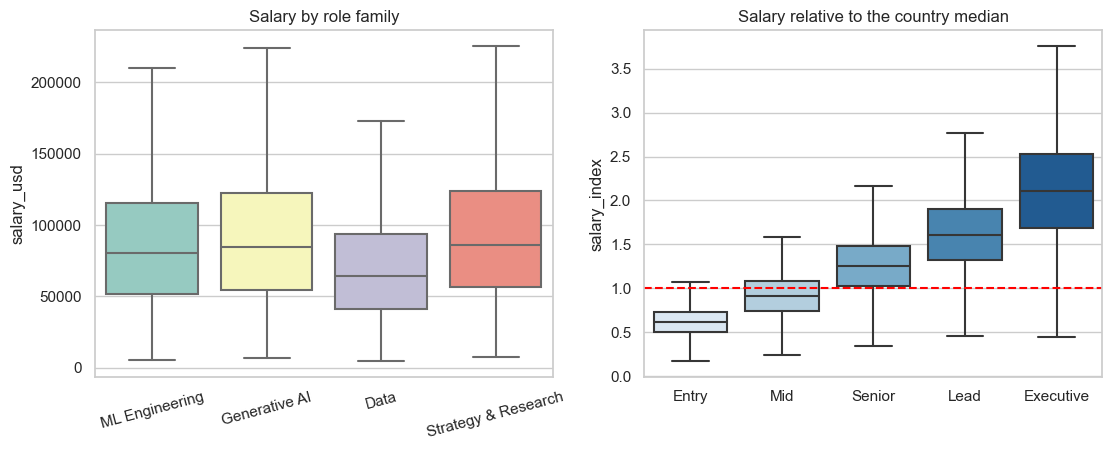

In [52]:
print(df.groupby('role_family')['salary_usd'].agg(['median', 'count']).sort_values('median', ascending=False).round(0))
print()
print(pd.crosstab(df['salary_band'], df['experience_level'], normalize='columns').mul(100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x='role_family', y='salary_usd', showfliers=False, palette='Set3', ax=axes[0])
axes[0].set_title('Salary by role family'); axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=15)
sns.boxplot(data=df, x='experience_level', y='salary_index', showfliers=False, palette='Blues', ax=axes[1])
axes[1].axhline(1, color='red', ls='--'); axes[1].set_title('Salary relative to the country median'); axes[1].set_xlabel('')
plt.show()

### 8. Outlier Detection

Outliers are values far from the rest. We use the **IQR rule**: a value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`. Before removing anything we check *who* the outliers are, because a very high salary can be perfectly real (for example an executive in the United States).

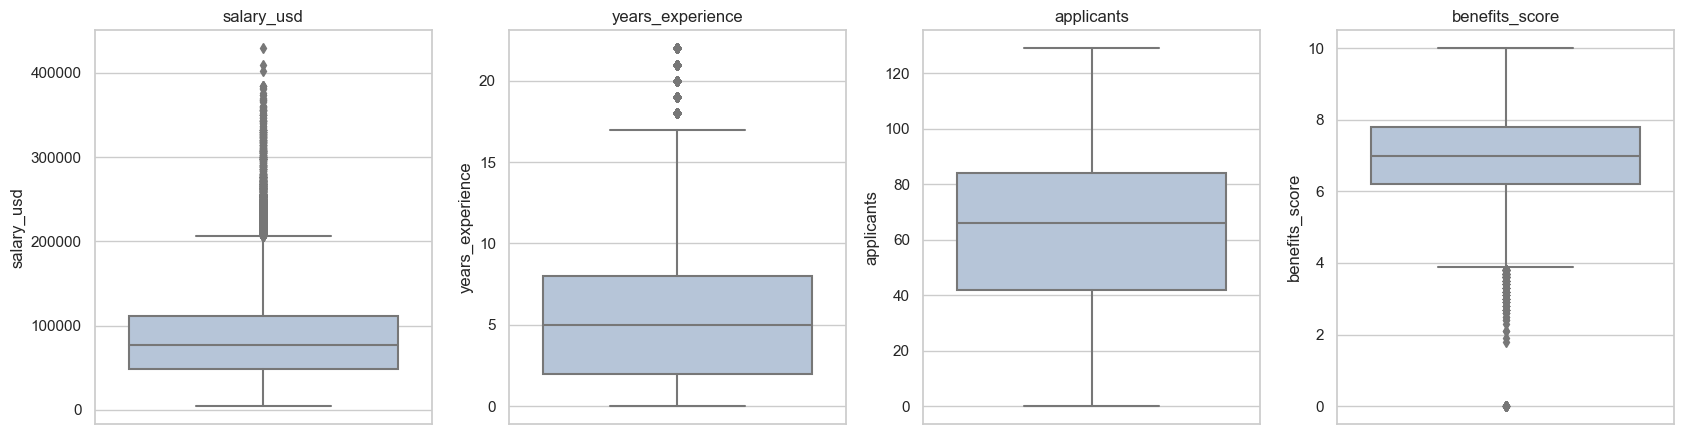

             column  lower bound  upper bound  outliers  % of rows
0        salary_usd     -45250.0     206350.0      1368       2.74
1  years_experience         -7.0         17.0      1094       2.19
2        applicants        -21.0        147.0         0       0.00
3    benefits_score          3.8         10.2       385       0.77
4  days_to_deadline        -11.0         85.0         0       0.00


In [53]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, col in zip(axes, ['salary_usd', 'years_experience', 'applicants', 'benefits_score']):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue'); ax.set_title(col)
plt.tight_layout()
plt.show()

def iqr_bounds(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ['salary_usd', 'years_experience', 'applicants', 'benefits_score', 'days_to_deadline']:
    lo, hi = iqr_bounds(df[col].dropna())
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 1), round(hi, 1), n, round(n / len(df) * 100, 2)])
print(pd.DataFrame(rows, columns=['column', 'lower bound', 'upper bound', 'outliers', '% of rows']))

In [54]:
lo, hi = iqr_bounds(df['salary_usd'])
df['is_salary_outlier'] = (df['salary_usd'] < lo) | (df['salary_usd'] > hi)
out = df[df['is_salary_outlier']]
print(f"Salary outliers: {len(out)} rows ({len(out) / len(df) * 100:.1f}%), bound = {hi:,.0f}\n")
print("By experience level (%):")
print(out['experience_level'].value_counts(normalize=True).mul(100).round(1))
print("\nBy country (top 5, %):")
print(out['company_location'].value_counts(normalize=True).mul(100).round(1).head(5))

# the same rule applied inside each experience level
grp_out = df.groupby('experience_level', observed=True)['salary_usd'].transform(lambda s: (s < iqr_bounds(s)[0]) | (s > iqr_bounds(s)[1]))
print("\nOutliers when judged inside each experience level:", grp_out.sum())

Salary outliers: 1368 rows (2.7%), bound = 206,350

By experience level (%):
Executive    52.4
Lead         33.1
Senior       13.7
Mid           0.6
Entry         0.2
Name: experience_level, dtype: float64

By country (top 5, %):
United States           69.6
Switzerland              4.8
Canada                   4.7
United Kingdom           4.4
United Arab Emirates     3.4
Name: company_location, dtype: float64

Outliers when judged inside each experience level: 329


Rows before: 49903 | after removing salary outliers: 48535
Median salary before / after: 77000.0 / 75300.0


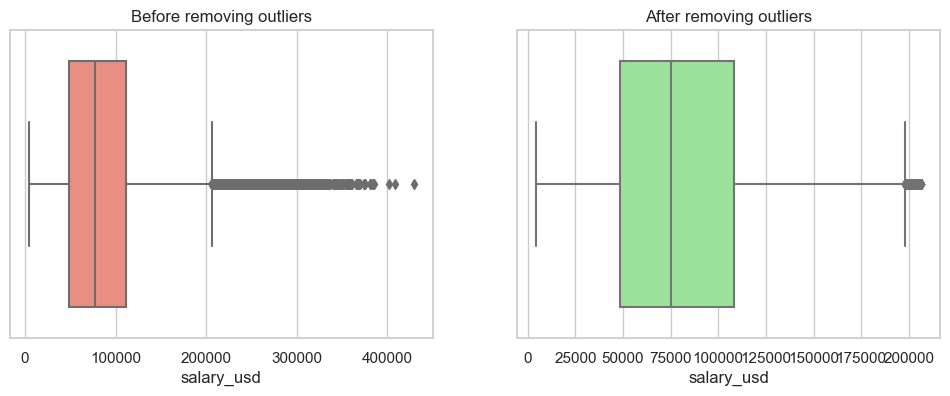

In [55]:
# Remove the global salary outliers for modelling (the cleaned data df stays unchanged)
df_no_outliers = df[~df['is_salary_outlier']].copy()
print("Rows before:", len(df), "| after removing salary outliers:", len(df_no_outliers))
print("Median salary before / after:", df['salary_usd'].median(), "/", df_no_outliers['salary_usd'].median())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['salary_usd'], ax=axes[0], color='salmon'); axes[0].set_title('Before removing outliers')
sns.boxplot(x=df_no_outliers['salary_usd'], ax=axes[1], color='lightgreen'); axes[1].set_title('After removing outliers')
plt.show()

### 9. Trend and Pattern Analysis

Here we look at how the data moves **over time** and then test how well the job features explain salary.

#### Q23. How does the number of postings change month by month?

posting_month
2025-10    4012
2025-11    3957
2025-12    4100
2026-01    4137
2026-02    3851
2026-03    4135
2026-04    4070
2026-05    4171
2026-06    3974
2026-07    4191
2026-08    4223
2026-09    2124
dtype: int64


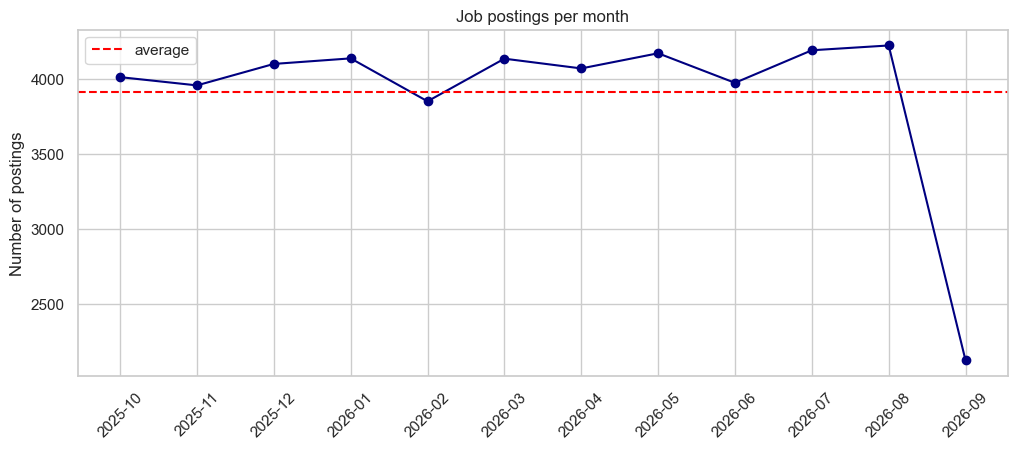


By quarter:
posting_quarter
2025Q4    12069
2026Q1    12123
2026Q2    12215
2026Q3    10538
Freq: Q-DEC, dtype: int64

By weekday:
Thursday     6850
Friday       6796
Wednesday    6782
Monday       6697
Sunday       6656
Saturday     6604
Tuesday      6560
Name: posting_weekday, dtype: int64


In [56]:
monthly = df.dropna(subset=['posting_date']).groupby('posting_month').size()
monthly.index = monthly.index.astype(str)
print(monthly)

plt.figure(figsize=(12, 4.5))
plt.plot(monthly.index, monthly.values, marker='o', color='navy')
plt.xticks(rotation=45); plt.title('Job postings per month'); plt.ylabel('Number of postings')
plt.axhline(monthly.mean(), color='red', ls='--', label='average'); plt.legend()
plt.show()

print("\nBy quarter:"); print(df.groupby('posting_quarter').size())
print("\nBy weekday:"); print(df['posting_weekday'].value_counts())

**Insight:** Hiring volume is flat, about 3,850 to 4,250 postings every month from October 2025 to August 2026, and the weekdays are equally busy (even weekends). The low September 2026 count (2,124) is because the data ends on 16 September 2026, not because hiring dropped. There is no growth trend or seasonality.

#### Q24. How long is the application window, and is there a seasonal pattern in salary?

count    43484.0
mean        36.9
std         13.6
min         14.0
25%         25.0
50%         37.0
75%         49.0
max         60.0
Name: days_to_deadline, dtype: float64

Median days to deadline by employment type:
employment_type
Full-time    37.0
Part-time    37.0
Contract     36.0
Freelance    37.0
Name: days_to_deadline, dtype: float64

Median salary by posting month:
posting_month
2025-10    78500.0
2025-11    77900.0
2025-12    76200.0
2026-01    76200.0
2026-02    76900.0
2026-03    77200.0
2026-04    77600.0
2026-05    75600.0
2026-06    77400.0
2026-07    77100.0
2026-08    76500.0
2026-09    77950.0
Name: salary_usd, dtype: float64


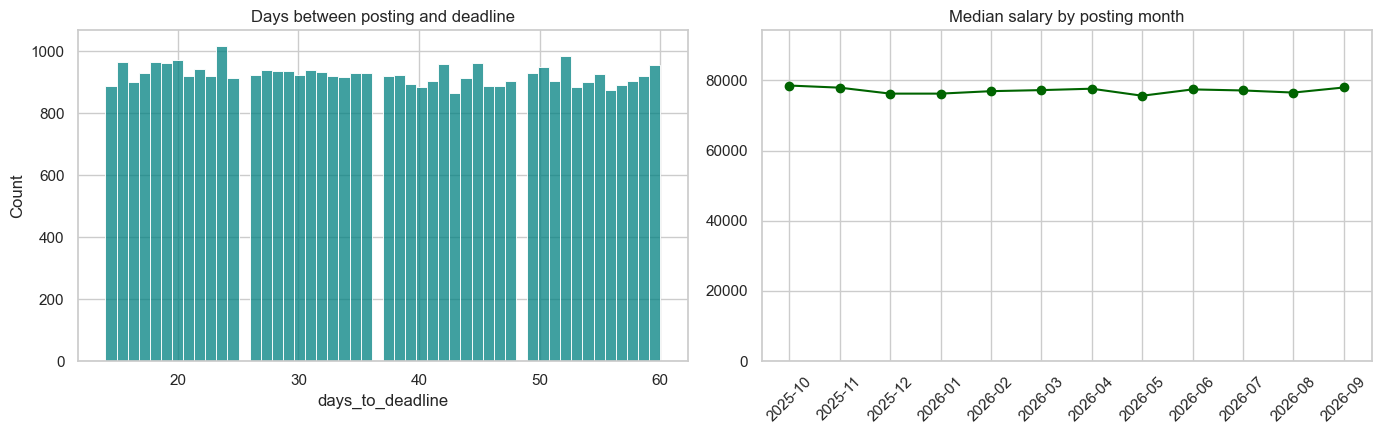

In [57]:
print(df['days_to_deadline'].describe().round(1))
print("\nMedian days to deadline by employment type:")
print(df.groupby('employment_type', observed=True)['days_to_deadline'].median())

monthly_salary = df.dropna(subset=['posting_date']).groupby('posting_month')['salary_usd'].median()
monthly_salary.index = monthly_salary.index.astype(str)
print("\nMedian salary by posting month:"); print(monthly_salary.round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df['days_to_deadline'].dropna(), bins=50, ax=axes[0], color='teal')
axes[0].set_title('Days between posting and deadline')
axes[1].plot(monthly_salary.index, monthly_salary.values, marker='o', color='darkgreen')
axes[1].set_title('Median salary by posting month'); axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, monthly_salary.max() * 1.2)
plt.tight_layout()
plt.show()

**Insight:** The application window is typically 37 days (between 14 and 60), and it is the same for every employment type (36 to 37 days). Median salary by posting month stays between 75,600 and 78,500 USD, within about 2% of the overall median, so there is no seasonal pattern in pay.

#### Q25. Can we predict salary from the job features, and which features matter most?

We train two models on the data without salary outliers: a simple **linear regression** (baseline) and a **random forest**. The target is `log_salary`, because salary is right-skewed. 80% of the rows train the model and 20% test it.

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

d = df_no_outliers
cat_feats = ['job_title', 'employment_type', 'company_size', 'company_location', 'industry']
X = pd.concat([
    pd.get_dummies(d[cat_feats].astype(str)),
    d[['experience_level_code', 'education_required_code', 'years_experience', 'remote_ratio', 'applicants', 'benefits_score']],
    d[['n_skills']].fillna(0)
], axis=1)
y = d['log_salary']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

models = {'Linear regression': LinearRegression(),
          'Random forest': RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42)}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    print(f"{name:18s} R2 = {r2_score(y_te, pred):.3f} | MAE = {mean_absolute_error(np.exp(y_te), np.exp(pred)):,.0f} USD")

Linear regression  R2 = 0.908 | MAE = 10,752 USD
Random forest      R2 = 0.875 | MAE = 12,833 USD


**Insight:** Job features explain salary well. The linear model reaches R² = 0.91 on unseen data (average error about 10,750 USD) and does slightly better than the random forest (R² = 0.88). The simple model wins because salary behaves like a product of effects (country x level x role), which becomes additive on the log scale. Two features carry most of the signal: **country (about 56% of the importance)** and **experience level (about 28%)**, followed by job title (6.6%) and employment type (5.1%). Remote ratio, education, benefits score, applicants and number of skills add almost nothing.

company_location           56.4
experience_level_code      27.6
job_title                   6.6
employment_type             5.1
company_size                1.3
industry                    1.1
years_experience            0.8
applicants                  0.4
benefits_score              0.4
n_skills                    0.1
education_required_code     0.1
remote_ratio                0.0
dtype: float64


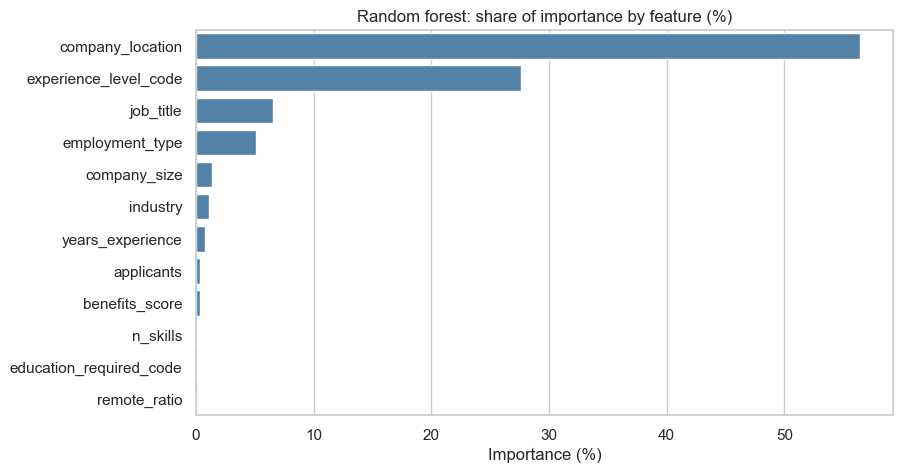

In [59]:
# group the one-hot columns back to their original feature and sum the importance
rf = models['Random forest']
imp = pd.Series(rf.feature_importances_, index=X.columns)
def origin(c):
    for f in cat_feats:
        if c.startswith(f + '_'): return f
    return c
imp_grouped = imp.groupby(origin).sum().sort_values(ascending=False)
print((imp_grouped * 100).round(1))

plt.figure(figsize=(9, 5))
sns.barplot(x=imp_grouped.values * 100, y=imp_grouped.index, color='steelblue')
plt.title('Random forest: share of importance by feature (%)'); plt.xlabel('Importance (%)'); plt.ylabel('')
plt.show()


### 10. Documentation & Reporting

#### Summary of the data

* The raw file had 51,750 rows and 18 columns. After cleaning, **49,903 postings** remain (duplicates removed, 97 rows without any usable salary dropped).
* The data covers 16 job titles, 20 countries and 14 industries, with posting dates from **October 2025 to mid-September 2026**.

#### Key findings

1. **Where you work and your level decide most of the pay.** In the Q25 model, country carries about 56% of the importance and experience level about 28%. A US posting pays about 4.5 times an Indian one (nominal USD), and an Executive earns about 3.4 times an Entry-level worker.
2. **Role matters, but less.** AI Research Scientist, LLM Engineer and AI Solutions Architect lead the median pay, and Data Analyst is lowest. Generative-AI and Research/Strategy families pay about 30% more than Data roles.
3. **Company side:** Large companies pay about 22% more than Small ones, and Finance, Technology and Consulting pay the most.
4. **Things that barely change salary:** education (about 5% from Associate to PhD), remote work (about 2%), benefits score (no link), the number of skills (no link), the posting month (no seasonality).
5. **Demand:** Machine Learning Engineer is the most posted role (13.5%). Python is requested in about 60% of postings with skills, then SQL and PyTorch. One posting in four is in the United States.
6. **Competition:** Remote jobs get about 2.3 times more applicants than on-site jobs, while the role itself makes almost no difference.
7. **Hiring volume is flat** month to month, with no trend or seasonality.

#### Recommendations

* **For job seekers:** Moving up one experience level or into a higher-paying market has a much larger pay effect than adding a degree. Roles in Generative AI, ML engineering and research pay more than data-analyst roles, so moving from analytics toward modelling and LLM work is the most useful skill path. Python and SQL are required in most postings, so they are the base. Do not choose a PhD for pay reasons alone.
* **For employers:** Remote postings can be offered **without a pay discount** and bring many more applicants, which helps when a role is hard to fill. Small companies pay about 18% less than large ones for the same kind of work, so they should compete on other things. The benefits score is unrelated to pay, so it should be reviewed separately and not assumed to make up for lower pay.
* **For analysts and data teams:** The raw file needed heavy cleaning. Using fixed lists for categories, validated numeric fields and ISO dates (`YYYY-MM-DD`) at entry would prevent most problems found here. `salary_local` / `salary_usd` is a useful consistency check.

#### Limitations

* Salaries are in USD at **fixed exchange rates** and are not adjusted for cost of living, so country comparisons describe nominal pay.
* A skill's pay "premium" mostly reflects the role that asks for it (Q16), and all relationships here are associations, not causes.
* About 6% of posting dates and 7% of deadlines are missing (including dd/mm vs mm/dd dates that could not be told apart). Postings without a skills list (about 5%) were not imputed.
* Several patterns are unusually even (flat monthly postings, identical role mix in every industry, no effect of benefits or skills count). This suggests the dataset may be simulated or synthetic, so conclusions should be treated as illustrative of this file and not as proof about the real job market.

#### Next steps

* Add cost-of-living or purchasing-power data to compare countries fairly.
* Try a gradient-boosting model with interaction terms (country x level), and test salary per role family.
* Build a dashboard of median pay by country, level and role.


In [60]:
# Save the cleaned data (the skills list is written as text separated by ';')
export = df.drop(columns=['skills_list']).copy()
export['skills'] = df['skills_list'].map(lambda l: ';'.join(l))
export.to_csv('ai_jobs_2026_clean.csv', index=False)
print("Saved ai_jobs_2026_clean.csv with shape", export.shape)

Saved ai_jobs_2026_clean.csv with shape (49903, 53)


**End of the project.**